# BI10 · Round 3 · Bước 2 — Business-as-Usual (BAU)

**Câu hỏi của bước:** *Nếu công ty **không thay đổi gì** (giữ nguyên nhân sự, cách làm, lead), mỗi shop sẽ ký được bao nhiêu contract và bao nhiêu funded volume mỗi tháng trong 10/2026 → 03/2027?*

**Định nghĩa (đề):** *"Business-as-Usual — what the shop is expected to achieve if current conditions and trends continue."* BAU **không** phải Current Actual (quá khứ), **không** phải Attainable Potential (có can thiệp), **không** phải Market Ceiling (lý thuyết).

| Hạng mục | Nội dung |
|---|---|
| Đầu vào | `Bước 1/shop_month_kpi.csv` và `Bước 1/cross_sell_attribution.csv` (Bước 1, mục 1.9, đã gồm cross-sell), `Round3_BI10_dataset/salesroom.xlsx` |
| Đầu ra | `shop_bau.csv` (1 dòng/shop), `shop_bau_monthly.csv`, `bau_params.json`, `shop_bau_dictionary.csv` |
| Phạm vi | **Chỉ Bước 2.** Không tính Attainable (B3), Market Ceiling (B4), gap (B5), ưu tiên (B6); không làm backtest chính thức, sensitivity, nhãn tin cậy (B7). Chỉ bàn giao hàm `run_backtest()` |
| Quy ước áp dụng | contract đã ký · đo bằng contract và funded volume · CA = TB 07–09/2026, BAU 10/2026–03/2027 · shop Active, VIRTUAL tính riêng, có nhãn shop mới |

**Mô hình BAU cuối cùng** (mỗi thành phần đều được kiểm chứng ở một giai đoạn riêng):

$$\text{BAU}_{i,m} = \underbrace{L_i}_{\text{mức nền 6 tháng (GĐ5)}} \times \underbrace{e^{\,\kappa\cdot \tilde g_i \cdot (h-\bar t_i)}}_{\text{phần trend còn kéo dài (GĐ5–6)}} \times \underbrace{f(\text{tuổi}_{i,m})}_{\text{vòng đời shop (GĐ3)}} \times \underbrace{\tfrac{d_m}{30.44}\, e^{\,B\cdot s_m}}_{\text{số ngày × mùa vụ (GĐ4)}}$$

*Lời thường:* "BAU = mức bán bình quân mỗi ngày của shop trong 6 tháng gần nhất, cộng phần xu hướng mà lịch sử chứng minh còn kéo dài, điều chỉnh theo tuổi shop (shop mới mở bán cao rồi giảm dần) và số ngày của từng tháng."

## Cấu trúc notebook & cách đọc

Notebook đi theo **11 giai đoạn**, đánh số khớp 1-1 với file `BI10_R03_Buoc2_BAU_Lo_trinh.docx`:

| GĐ | Mục đích | Các bước |
|---|---|---|
| 0 | Chuẩn bị công cụ, tham số | 0.1 Công cụ · 0.2 CFG · 0.3 Tìm file |
| 1 | Khóa data contract với Bước 1 | 1.1 Đọc · 1.2 Schema · 1.3 Phòng vệ · 1.4 Toàn vẹn · 1.5 Đối soát CA |
| 2 | Xác định tháng nào được dùng để đo | 2.1 Tuổi shop · 2.2 Tháng khai trương · 2.3 Số ngày · 2.4 Ngành hàng · 2.5 Trạng thái dữ liệu |
| 3 | Chẩn đoán chuỗi trước khi chọn phương pháp | 3.1 Phân rã tăng trưởng · 3.2 Same-store · 3.3 Vòng đời · 3.4 Nhiễu · 3.5 Tập trung |
| 4 | Mùa vụ có kiểm định | 4.1 Link relatives · 4.2 Chỉ số mùa vụ · 4.3 Lặp lại · 4.4 Sốc 11/2025 · 4.5 Tết theo ngành · 4.6 Hệ số tháng |
| 5 | Trend 6 tháng từng shop | 5.1 Hàm ước lượng · 5.2 Mức nền & trend · 5.3 Nhiễu φ · 5.4 Nhãn · 5.5 Lọc nhiễu |
| 6 | Trend kéo dài bao nhiêu | 6.1–6.2 Hiệu chỉnh κ · 6.3 Kiểm tra trực quan · 6.4 Nhãn có dự báo được không |
| 7 | Lắp ráp BAU contract | 7.1 Công thức · 7.2 Quy tắc biên · 7.3 Tổng hợp |
| 8 | BAU funded & cross-sell | 8.1 Ticket · 8.2 Funded · 8.3 Cross-sell · 8.4 Ký nơi khác · 8.5 Tổng |
| 9 | Kiểm tra nội bộ chọn thành phần | 9.1–9.2 So 4 phương án · 9.3 Theo tuổi shop |
| 10 | Trình bày lời thường | 10.1 Câu chuẩn · 10.2 Bảng/biểu đồ · 10.3 Điểm ngược trực giác |
| 11 | Xuất file & bàn giao | 11.1 Xuất · 11.2 Từ điển |

**Khuôn trình bày của mỗi bước:** **Mục đích** → **Cách làm** → khối code → **Hậu kiểm định** → **Phân tích kết quả**, gồm ba phần:
- **① Pattern:** điều nhìn thấy trực tiếp trong số liệu hoặc biểu đồ vừa chạy.
- **② Insight:** pattern đó nói gì về hành vi của shop và mạng lưới, và có ý nghĩa gì cho BAU và cho quản lý.
- **③ Câu hỏi · Giả thuyết · Bàn giao:** điều cần kiểm chứng tiếp, tiền đề chuyển cho bước khác (→ B3, B5, B6, B7, Sales), hoặc đề xuất bổ sung.

Mỗi ý được gắn nhãn **[Tin cậy · Giá trị]** và xếp **từ tin cậy cao, giá trị cao xuống thấp**.
- *Tin cậy Cao* = đo trực tiếp trên toàn bộ dữ liệu hoặc đã kiểm định.
- *Tin cậy TB* = có bằng chứng nhưng mẫu nhỏ hoặc chỉ quan sát một lần.
- *Tin cậy Thấp* = suy luận, cần xác nhận thêm.

---
## GĐ0 · Chuẩn bị công cụ và tham số

**Mục đích giai đoạn:** dựng môi trường chạy lại được trên Colab; gom **mọi con số "chốt"** vào một chỗ để Bước 7 làm sensitivity chỉ cần đổi một dòng.

**Phương pháp tổng thể:** chọn công cụ đơn giản, minh bạch (0.1) → khai báo tham số (0.2) → tự tìm file đầu vào (0.3).

### GĐ0.1 · Chọn công cụ
**Mục đích:** chọn công cụ phù hợp với kích thước dữ liệu và yêu cầu "simple and transparent" của đề.

**Cách làm (đánh giá công cụ):**
1. `pandas` + `numpy`: tính toán vector hóa trên khoảng 250 nghìn dòng shop×tháng. Không cần DuckDB vì đầu vào là bảng tổng hợp 33 MB.
2. `scipy`: kiểm định và khớp đường cong (`curve_fit`).
3. `matplotlib`: biểu đồ, tiêu đề tiếng Anh.
4. **Không dùng machine learning:** mọi tham số đều ước lượng bằng công thức đóng, giải thích được trước giám khảo.

In [1]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from scipy.optimize import curve_fit

try:  # Colab / Jupyter
    from IPython.display import display, Markdown
except ImportError:  # pragma: no cover
    pass

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)   # cảnh báo đổi phiên bản của pandas, không ảnh hưởng kết quả
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.2.6


### GĐ0.2 · Khai báo tham số `CFG`
**Mục đích:** mọi lựa chọn phân tích nằm ở một chỗ, có chú thích lý do.

**Cách làm:** khai báo dict `CFG`: tháng thực tế cuối, horizon, cửa sổ trend, ngưỡng tối thiểu, các thời điểm gốc dùng để hiệu chỉnh.

In [2]:
CFG = {
    "FIRST_MONTH": pd.Timestamp("2025-01-01"),
    "LAST_ACTUAL": pd.Timestamp("2026-09-01"),        # tháng thực tế cuối cùng
    "HORIZON": 6,                                     # 10/2026 → 03/2027 (QƯ3)
    "CA_START": pd.Timestamp("2026-07-01"),           # Current Actual = TB 07–09/2026 (QƯ3)
    "WINDOW": 6,                                      # cửa sổ trend 6 tháng
    "NAIVE_WINDOW": 3,                                # benchmark Bước 7: TB 3 tháng trước
    "MIN_VALID_FOR_TREND": 4,                         # cần ≥4 tháng đầy đủ để ước lượng độ dốc
    "TREND_CAP": 0.15,                                # chặn |trend sau lọc nhiễu| ≤ 15%/tháng
    "SEASON_MIN_PANEL": 100,                          # tháng có <100 shop so sánh được thì bỏ khỏi mùa vụ
    "KAPPA_ORIGINS": pd.date_range("2025-06-01", "2026-03-01", freq="MS"),  # gốc hiệu chỉnh κ
    "KAPPA_MIN_SHOPS": 150,
    "HOLDOUT_ORIGIN": pd.Timestamp("2026-03-01"),     # kiểm tra nội bộ: đứng ở 03/2026
    "SMOOTH_C": 0.5,                                  # hằng số làm trơn log cho số đếm nhỏ
    "XSELL_FIRST_FULL_MONTH": pd.Timestamp("2026-02-01"),  # lead bắt đầu 31/12/2025 → bỏ 01/2026
}
MEAN_DAYS = 365.25 / 12
FC_MONTHS = pd.date_range(CFG["LAST_ACTUAL"] + pd.DateOffset(months=1), periods=CFG["HORIZON"], freq="MS")
print("Tháng dự báo:", [m.strftime("%Y-%m") for m in FC_MONTHS])

Tháng dự báo: ['2026-10', '2026-11', '2026-12', '2027-01', '2027-02', '2027-03']


### GĐ0.3 · Tìm file đầu vào
**Mục đích:** mọi thành viên và giám khảo chạy lại được mà không phải sửa đường dẫn.

**Cách làm:** notebook tự tìm thư mục gốc của bài (thư mục có `Bước 1`). Hai bảng đầu vào do Bước 1 tạo ra ở mục 1.9 (`Bước 1/shop_month_kpi.csv`, `Bước 1/cross_sell_attribution.csv`); bảng shop lấy từ dữ liệu gốc của Ban tổ chức (`Round3_BI10_dataset/salesroom.xlsx`). Kết quả ghi vào thư mục `Bước 2/`.

In [3]:
from pathlib import Path
ROOT = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q / "Bước 1").exists())   # thư mục gốc của bài
PATH_KPI = str(ROOT / "Bước 1" / "shop_month_kpi.csv")
PATH_XSELL = str(ROOT / "Bước 1" / "cross_sell_attribution.csv")
PATH_SALESROOM = str(ROOT / "Round3_BI10_dataset" / "salesroom.xlsx")
OUT_DIR = str(ROOT / "Bước 2")
for f in (PATH_KPI, PATH_XSELL, PATH_SALESROOM):
    assert os.path.exists(f), f"Không tìm thấy {f}"
print("KPI       :", os.path.relpath(PATH_KPI, ROOT))
print("Salesroom :", os.path.relpath(PATH_SALESROOM, ROOT))
print("Cross-sell:", os.path.relpath(PATH_XSELL, ROOT))

KPI       : Bước 1/shop_month_kpi.csv
Salesroom : Round3_BI10_dataset/salesroom.xlsx
Cross-sell: Bước 1/cross_sell_attribution.csv


**Kết quả GĐ0:** tìm đủ 3 file; 6 tháng dự báo đúng 10/2026 → 03/2027. Không có kết quả phân tích ở giai đoạn này.

---
## GĐ1 · Nạp dữ liệu & khóa data contract với Bước 1

**Mục đích giai đoạn:** bảo đảm BAU được đo bằng **cùng một thước** với Current Actual của Bước 1 (cùng định nghĩa contract đã ký, funded volume, tháng ký, shop Active). Nếu khác thước, mọi so sánh BAU − CA là vô nghĩa.

**Phương pháp tổng thể:** đọc với kiểu dữ liệu khóa cứng (1.1) → kiểm tra schema (1.2) → phòng vệ dữ liệu bẩn (1.3) → kiểm tra toàn vẹn (1.4) → đối soát CA với số Bước 1 đã báo cáo (1.5).

### GĐ1.1–1.3 · Đọc file, khóa schema, phòng vệ
**Mục đích:** đọc đúng kiểu dữ liệu và dừng ngay nếu thiếu cột.

**Cách làm:**
1. Đọc `shop_month_kpi.csv`; `shop_id` đọc là chuỗi (vì có giá trị `VIRTUAL`), cột tháng đọc là ngày.
2. So với danh sách 30 cột chuẩn; bảng của Bước 1 có 28 cột (không có hai cột lead `leads_failed`, `leads_open`, notebook không dùng tới); `assert` đủ 14 cột bắt buộc.
3. Ép các cột số về dạng số, ±∞ → NaN, cột đếm và cột tiền thiếu → 0 (Bước 1 đã COALESCE).

In [4]:
EXPECTED_KPI_COLS = [
    "shop_id", "shop_category", "salesroom_model", "salesroom_province", "salesroom_area", "month",
    "applications", "approved_from_apply_cohort", "approval_rate", "signed_contracts", "funded_volume",
    "avg_ticket_size", "insurance_rate", "headcount_sa", "productivity", "risk_eligible_contracts",
    "first_payment_default_contracts", "risk_rate", "first_seen_month", "shop_age_group", "leads_created",
    "leads_deal", "conversion_rate", "leads_failed", "leads_open", "cross_sell_contracts",
    "cross_sell_funded_volume", "cross_sell_avg_ticket_size", "cross_sell_booked_same_shop",
    "cross_sell_booked_elsewhere_or_online",
]
REQUIRED_COLS = ["shop_id", "month", "signed_contracts", "funded_volume", "first_seen_month", "shop_age_group",
                 "shop_category", "salesroom_model", "salesroom_province", "salesroom_area", "headcount_sa",
                 "cross_sell_contracts", "cross_sell_funded_volume", "cross_sell_booked_elsewhere_or_online"]
COUNT_COLS = ["signed_contracts", "cross_sell_contracts", "cross_sell_booked_same_shop",
              "cross_sell_booked_elsewhere_or_online"]
TEXT_COLS = ("shop_id", "shop_category", "salesroom_model", "salesroom_province", "salesroom_area", "month",
             "first_seen_month", "shop_age_group")

# 1.1 Đọc với kiểu dữ liệu khóa cứng
kpi = pd.read_csv(PATH_KPI, dtype={"shop_id": "string"}, parse_dates=["month", "first_seen_month"])
# 1.2 Schema
missing = sorted(set(REQUIRED_COLS) - set(kpi.columns))
assert not missing, f"Thiếu cột bắt buộc từ Bước 1: {missing}"
extra = sorted(set(kpi.columns) - set(EXPECTED_KPI_COLS))
# 1.3 Phòng vệ
num_cols = [c for c in EXPECTED_KPI_COLS if c in kpi.columns and c not in TEXT_COLS]
kpi[num_cols] = kpi[num_cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
money_count = COUNT_COLS + ["funded_volume", "cross_sell_funded_volume"]
kpi[money_count] = kpi[money_count].fillna(0)
kpi["shop_id"] = kpi["shop_id"].astype(str)
kpi = kpi.sort_values(["shop_id", "month"], ignore_index=True)
print(f"Đọc {len(kpi):,} dòng × {kpi.shape[1]} cột | thiếu cột: {missing} | cột lạ: {extra}")

Đọc 246,813 dòng × 28 cột | thiếu cột: [] | cột lạ: []


### GĐ1.4–1.5 · Kiểm tra toàn vẹn & đối soát Current Actual
**Mục đích:** chứng minh bảng đầu vào là lưới đầy đủ, sạch, và cho đúng CA mà Bước 1 đã báo cáo.

**Cách làm:**
1. Số dòng = số shop × 21 tháng; không trùng (shop_id, month); không âm; `signed_contracts` là số nguyên.
2. Cộng 07–09/2026 bốn con số (contract, funded, cross-sell contract, cross-sell funded) và so với Bước 1.

**Hậu kiểm định:** mỗi dòng của bảng là một điều kiện *phải đúng*; các điều kiện then chốt có `assert`. Nếu sai thì sửa ở Bước 1, không vá ở Bước 2.

In [5]:
months_all = pd.date_range(CFG["FIRST_MONTH"], CFG["LAST_ACTUAL"], freq="MS")
ca_mask = kpi["month"].between(CFG["CA_START"], CFG["LAST_ACTUAL"])
checks = pd.DataFrame([
    ("Số dòng", len(kpi), "= số shop × 21 tháng"),
    ("Số shop (shop_id)", kpi["shop_id"].nunique(), "shop Active + 1 nhóm VIRTUAL"),
    ("Số tháng", kpi["month"].nunique(), "21 (01/2025–09/2026)"),
    ("Lưới đầy đủ shop×tháng", int(len(kpi) == kpi["shop_id"].nunique() * len(months_all)), "1 = đúng"),
    ("Trùng (shop_id, month)", int(kpi.duplicated(["shop_id", "month"]).sum()), "0"),
    ("Giá trị âm ở cột đếm/tiền", int((kpi[COUNT_COLS + ["funded_volume"]] < 0).sum().sum()), "0"),
    ("signed_contracts không nguyên", int((kpi["signed_contracts"] % 1 != 0).sum()), "0"),
    ("CA 07–09/2026: signed_contracts", int(kpi.loc[ca_mask, "signed_contracts"].sum()), "Bước 1 (mục 1.9): 113.038"),
    ("CA 07–09/2026: funded_volume (tỷ)", round(kpi.loc[ca_mask, "funded_volume"].sum() / 1e9, 1), "Bước 1 (mục 1.9): ~1.551,7"),
    ("CA 07–09/2026: cross_sell_contracts", int(kpi.loc[ca_mask, "cross_sell_contracts"].sum()), "Bước 1 (mục 1.9): 25.721"),
    ("CA 07–09/2026: cross_sell_funded (tỷ)", round(kpi.loc[ca_mask, "cross_sell_funded_volume"].sum() / 1e9, 1), "Bước 1 (mục 1.9): ~326,7"),
], columns=["Kiểm tra", "Kết quả", "Kỳ vọng"])
display(checks)
assert len(kpi) == kpi["shop_id"].nunique() * len(months_all)
assert kpi.duplicated(["shop_id", "month"]).sum() == 0
assert (kpi[COUNT_COLS + ["funded_volume"]] >= 0).all().all()

,Kiểm tra,Kết quả,Kỳ vọng
0,Số dòng,"246,813.0000",= số shop × 21 tháng
1,Số shop (shop_id),"11,753.0000",shop Active + 1 nhóm VIRTUAL
2,Số tháng,21.0000,21 (01/2025–09/2026)
3,Lưới đầy đủ shop×tháng,1.0000,1 = đúng
4,"Trùng (shop_id, month)",0.0000,0
5,Giá trị âm ở cột đếm/tiền,0.0000,0
6,signed_contracts không nguyên,0.0000,0
7,CA 07–09/2026: signed_contracts,"113,038.0000",Bước 1 (mục 1.9): 113.038
8,CA 07–09/2026: funded_volume (tỷ),"1,551.7000","Bước 1 (mục 1.9): ~1.551,7"
9,CA 07–09/2026: cross_sell_contracts,"25,721.0000",Bước 1 (mục 1.9): 25.721


**Phân tích kết quả GĐ1**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** 246.813 dòng = 11.753 shop_id × 21 tháng (11.752 shop vật lý Active + 1 nhóm VIRTUAL); 0 dòng trùng, 0 giá trị âm, 0 số lẻ.
- **[Tin cậy Cao · Giá trị Cao]** CA 07–09/2026 khớp đến từng đơn vị: **113.038 contract · 1.551,7 tỷ · 25.721 contract cross-sell · 326,7 tỷ**.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** BAU và CA dùng **chung một thước đo**. Mọi chênh lệch BAU − CA ở GĐ7–8 là do dự báo, không phải do định nghĩa. Giám khảo hỏi "BAU lấy số từ đâu" thì trả lời ngay được: từ đúng bảng KPI của Bước 1.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Cả nhóm:** nếu Bước 1 đổi bất kỳ quy ước nào (giới hạn 30 ngày nối lead, cách tính billing CC/BNPL), phải chạy lại notebook này. Mọi thứ tự động; ô đối soát sẽ báo ngay nếu lệch.

---
## GĐ2 · Dựng panel shop × tháng chuẩn cho dự báo

**Mục đích giai đoạn:** xác định **tháng nào của shop nào được phép dùng** để đo mức nền và trend. Bảng của Bước 1 là lưới đủ 21 tháng cho mọi shop, nên có cả các dòng "bán 0" **trước khi shop tồn tại** và **tháng khai trương thiếu ngày**. Cả hai làm méo phép đo.

**Phương pháp tổng thể:** tính tuổi shop (2.1) → chứng minh tháng khai trương thiếu ngày và loại khỏi phép đo (2.2) → hệ số số ngày (2.3) → ghép ngành hàng (2.4) → phân nhóm trạng thái dữ liệu (2.5).

### GĐ2.1 · Tính tuổi shop
**Mục đích:** tách "shop chưa tồn tại" khỏi "shop tồn tại nhưng bán 0".

**Cách làm:** `age` = số tháng từ `first_seen_month` (tháng đầu shop có hồ sơ hoặc contract) đến tháng đang xét. Khi đó `in_scope` = age ≥ 0 (shop đã tồn tại), `valid` = age ≥ 1 (tháng đầy đủ).

In [6]:
def month_diff(a, b):
    """Số tháng giữa hai Series datetime (a − b), vector hóa."""
    return (a.dt.year - b.dt.year) * 12 + (a.dt.month - b.dt.month)


panel = kpi.assign(age=lambda d: month_diff(d["month"], d["first_seen_month"]),
                   dim=lambda d: d["month"].dt.days_in_month,
                   moy=lambda d: d["month"].dt.month)
panel["in_scope"] = panel["age"].ge(0)          # shop đã xuất hiện
panel["valid"] = panel["age"].ge(1)             # tháng đầy đủ (không phải tháng khai trương)
panel["is_physical"] = panel["shop_id"].ne("VIRTUAL")
display(pd.Series({
    "shop×tháng trước khi shop xuất hiện (bỏ)": int((panel["age"] < 0).sum()),
    "shop×tháng của shop chưa từng phát sinh (bỏ)": int(panel["first_seen_month"].isna().sum()),
    "shop×tháng trong phạm vi (age ≥ 0)": int(panel["in_scope"].sum()),
    "shop×tháng đầy đủ (age ≥ 1)": int(panel["valid"].sum()),
}).rename("số dòng").to_frame())

,số dòng
shop×tháng trước khi shop xuất hiện (bỏ),110881
shop×tháng của shop chưa từng phát sinh (bỏ),45633
shop×tháng trong phạm vi (age ≥ 0),90299
shop×tháng đầy đủ (age ≥ 1),80719


### GĐ2.2 · Chứng minh tháng khai trương thiếu ngày → loại khỏi phép đo
**Mục đích:** có bằng chứng số liệu (không chỉ suy luận) rằng tháng khai trương không đại diện cho sức bán.

**Cách làm:** trên cùng tập shop đã quan sát đủ tuổi 0, 1, 2, so contract bình quân ở từng tuổi.

In [7]:
has3 = panel.loc[panel["is_physical"]].groupby("shop_id")["age"].max().ge(2)
early = panel.loc[panel["shop_id"].isin(has3[has3].index) & panel["age"].between(0, 2)]
launch_tbl = early.groupby("age")["signed_contracts"].agg(["mean", "median", "size"])
launch_tbl["so với tuổi 1"] = launch_tbl["mean"] / launch_tbl.loc[1, "mean"] - 1
display(launch_tbl)
print(f"Số tháng khai trương bị loại khỏi phép đo mức nền: {int(panel['age'].eq(0).sum()):,}")

,mean,median,size,so với tuổi 1
age,,,,
0.0000,2.9410,1.0000,8459,-0.3251
1.0000,4.3575,1.0000,8459,0.0000
2.0000,4.3395,1.0000,8459,-0.0041


Số tháng khai trương bị loại khỏi phép đo mức nền: 9,580


**Phân tích kết quả GĐ2.1–2.2**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Trên cùng 8.459 shop, tháng khai trương chỉ đạt **2,94 contract**, so với **4,36** ở tháng đầy đủ đầu tiên (**−33%**) và 4,34 ở tháng thứ hai.
- **[Tin cậy Cao · Giá trị TB]** Trong số 90.299 shop×tháng thuộc phạm vi, có **9.580 tháng khai trương** (10,6%).

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Shop thường mở giữa tháng, nên tháng khai trương là tháng "thiếu ngày", không phải tháng "bán kém". Nếu đưa vào, mức nền bị kéo xuống và mọi shop mới đều có một **"trend tăng giả"** từ tháng 0 sang tháng 1. Loại tháng này là điều kiện để trend ở GĐ5 có ý nghĩa.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 3 (peer group, benchmark):** khi so KPI giữa các shop, cũng nên loại tháng khai trương. Nếu không, shop mới bị xếp hạng thấp oan.
- **Đề xuất bổ sung (nếu có dữ liệu ngày):** dùng `SALESROOM_START` để quy đổi tháng khai trương theo số ngày hoạt động thực tế, thay vì bỏ hẳn.

### GĐ2.3 · Hệ số số ngày
**Mục đích:** so sánh được tháng với tháng: tháng 2 có 28 ngày, tháng 3 có 31 ngày, nên tháng 2 tự nhiên thấp hơn khoảng 10% dù sức bán mỗi ngày như nhau.

**Cách làm:** hệ số ngày = số ngày của tháng / 30,44 (số ngày bình quân một tháng).

In [8]:
display(pd.DataFrame({"tháng dự báo": FC_MONTHS.strftime("%m/%Y"), "số ngày": FC_MONTHS.days_in_month,
                      "hệ số ngày": FC_MONTHS.days_in_month / MEAN_DAYS}).set_index("tháng dự báo").T)

tháng dự báo,10/2026,11/2026,12/2026,01/2027,02/2027,03/2027
số ngày,31.0000,30.0000,31.0000,31.0000,28.0000,31.0000
hệ số ngày,1.0185,0.9856,1.0185,1.0185,0.9199,1.0185


**Kết quả GĐ2.3:** trong 6 tháng dự báo, 02/2027 có hệ số 0,920 (28 ngày), 11/2026 là 0,986, còn các tháng 31 ngày là 1,018. → **[Tin cậy Cao · Giá trị TB]** Riêng hiệu ứng số ngày đã làm BAU tháng 2 thấp hơn tháng 3 khoảng 10%. Đây **không** phải dấu hiệu shop yếu đi.

### GĐ2.4 · Ghép ngành hàng chính của shop
**Mục đích:** có cột `SALESROOM_PRODUCT` (CD/TW/NS) để phân tích mùa vụ theo ngành (GĐ4.5) và mượn số liệu theo nhóm cỡ × ngành (GĐ7, GĐ8). `shop_month_kpi` của Bước 1 không có cột này.

**Cách làm:** đọc `salesroom.xlsx`, giữ shop Active, ghép theo `shop_id`.

In [9]:
sr = (pd.read_excel(PATH_SALESROOM) if PATH_SALESROOM.endswith(".xlsx") else pd.read_csv(PATH_SALESROOM))
sr.columns = [c.upper() for c in sr.columns]
sr["shop_id"] = sr["SKP_SALESROOM"].astype(str)
sr_attr = (sr.loc[sr["SALESROOM_STATUS"].str.upper().eq("ACTIVE"), ["shop_id", "SALESROOM_PRODUCT", "SALESROOM_START"]]
             .drop_duplicates("shop_id"))
sr_attr["SALESROOM_START"] = pd.to_datetime(sr_attr["SALESROOM_START"], dayfirst=True, errors="coerce")
panel = panel.merge(sr_attr, on="shop_id", how="left")
panel["SALESROOM_PRODUCT"] = panel["SALESROOM_PRODUCT"].fillna(
    pd.Series(np.where(panel["shop_id"].eq("VIRTUAL"), "VIRTUAL", "UNKNOWN"), index=panel.index))
print("Shop thiếu ngành hàng sau khi ghép:",
      int(panel.loc[panel["month"].eq(CFG["LAST_ACTUAL"]), "SALESROOM_PRODUCT"].eq("UNKNOWN").sum()))

Shop thiếu ngành hàng sau khi ghép: 0


**Kết quả GĐ2.4:** 0 shop thiếu ngành hàng → **[Tin cậy Cao]** mọi phân tích theo ngành và theo nhóm cỡ × ngành ở các giai đoạn sau đều phủ đủ 100% shop.

### GĐ2.5 · Phân nhóm trạng thái dữ liệu tại 09/2026
**Mục đích:** biết trước nhóm shop nào **không** áp dụng được "trend 6 tháng" để thiết kế quy tắc biên (GĐ7.2).

**Cách làm:** chia 5 nhóm theo `first_seen_month`, tuổi tại 09/2026 và `shop_age_group` (nhãn của Bước 1).

In [10]:
last = panel.loc[panel["month"].eq(CFG["LAST_ACTUAL"])].set_index("shop_id")
shops = last[["shop_category", "salesroom_model", "SALESROOM_PRODUCT", "salesroom_province", "salesroom_area",
              "first_seen_month", "shop_age_group", "age"]].rename(columns={"age": "age_at_origin"})
shops["data_status"] = np.select(
    [shops.index == "VIRTUAL", shops["first_seen_month"].isna(), shops["age_at_origin"].eq(0),
     shops["shop_age_group"].eq("shop mới")],
    ["VIRTUAL (nhóm online, báo cáo riêng)", "Chưa phát sinh doanh số",
     "Mới mở trong 09/2026 (chỉ có tháng khai trương)", "Shop mới (<6 tháng dữ liệu)"],
    default="Shop hiện hữu (≥6 tháng dữ liệu)")
display(shops["data_status"].value_counts().rename("số shop").to_frame()
        .assign(tỷ_trọng=lambda d: d["số shop"] / d["số shop"].sum()))
never_profile = (shops.loc[shops["data_status"].eq("Chưa phát sinh doanh số")]
                 .groupby("salesroom_model").size()
                 .div(shops.loc[shops.index != "VIRTUAL"].groupby("salesroom_model").size())
                 .rename("tỷ lệ shop chưa từng bán"))
display(never_profile.to_frame())
display(shops.loc[shops["data_status"].eq("Chưa phát sinh doanh số"), "shop_category"].value_counts()
        .rename("shop chưa từng bán theo cỡ").to_frame())

,số shop,tỷ_trọng
data_status,,
Shop hiện hữu (≥6 tháng dữ liệu),5901,0.5021
Shop mới (<6 tháng dữ liệu),3183,0.2708
Chưa phát sinh doanh số,2173,0.1849
Mới mở trong 09/2026 (chỉ có tháng khai trương),495,0.0421
"VIRTUAL (nhóm online, báo cáo riêng)",1,0.0001


,tỷ lệ shop chưa từng bán
salesroom_model,
Aldi,0.2507
Non-Aldi,0.1584


,shop chưa từng bán theo cỡ
shop_category,
Small,990
Medium,912
Big,271


**Phân tích kết quả GĐ2.5**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Hiện hữu **5.901 (50,2%)** · Shop mới **3.183 (27,1%)** · Mới mở 09/2026 **495 (4,2%)** · **Chưa từng phát sinh 2.173 (18,5%)** · VIRTUAL 1. Tổng shop mới 3.678 khớp Bước 1.
- **[Tin cậy Cao · Giá trị TB]** Tỷ lệ shop Active nhưng chưa từng bán: **Aldi 25%**, so với **Non-Aldi 16%**. Trong nhóm chưa từng bán có **271 shop Big**.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Khoảng **một nửa** số shop không đủ 6 tháng dữ liệu để tính trend theo nghĩa đen. Vì vậy BAU cần **quy tắc biên được viết rõ** cho từng nhóm (GĐ7.2), không để code tự xử lý ngầm.
- **[Tin cậy TB · Giá trị TB]** Shop Aldi (nhân viên cửa hàng tự làm hồ sơ) "đứng im" nhiều hơn hẳn. Đây là tín hiệu về **chất lượng kích hoạt đối tác**, không phải về nhu cầu.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 3/5:** 2.173 shop có BAU = 0. Giả thuyết cần kiểm chứng: gap của nhóm này (đặc biệt 271 shop Big) là **gap kích hoạt**, phải xử lý khác với gap năng suất.
- **→ Bước 6:** cân nhắc tách riêng nhóm "Active nhưng chưa từng bán" khỏi danh sách ưu tiên đầu tư thêm SA.
- **Câu hỏi cho Sales/BTC:** vì sao các shop này ở trạng thái Active mà không phát sinh hồ sơ nào trong 21 tháng (mới ký hợp tác, hay đã ngừng nhưng chưa cập nhật trạng thái)?

---
## GĐ3 · Chẩn đoán cấu trúc chuỗi doanh số (trước khi chọn phương pháp)

**Mục đích giai đoạn:** trả lời 4 câu hỏi quyết định **cách** làm BAU:
- (Q1) Tăng trưởng đến từ mở shop hay từ mỗi shop bán nhiều hơn?
- (Q2) Shop mới có vòng đời gì?
- (Q3) Doanh số của một shop nhiễu đến mức nào?
- Doanh số tập trung vào bao nhiêu shop?

**Phương pháp tổng thể:** phân rã tăng trưởng (3.1) → chỉ số same-store (3.2) → đường vòng đời trong cùng shop (3.3) → đo nhiễu và ngưỡng phát hiện trend (3.4) → mức tập trung (3.5).

### GĐ3.1 · Phân rã tăng trưởng mạng lưới
**Mục đích:** kiểm chứng giả thuyết H1 "tăng trưởng đến từ mở shop" → quyết định có được dùng trend mạng lưới cho từng shop hay không.

**Cách làm:** ln(Tổng_T / Tổng_0) = ln(Số shop_T / Số shop_0) + ln(Bình quân/shop_T / Bình quân/shop_0). Phần thứ nhất là "mở shop", phần thứ hai là "mỗi shop bán nhiều hơn".

In [11]:
phys = panel.loc[panel["is_physical"]]
net = (phys.groupby("month")
           .agg(signed=("signed_contracts", "sum"), shops_in_scope=("in_scope", "sum"))
           .assign(per_shop=lambda d: d["signed"] / d["shops_in_scope"]))
first_m, last_m = net.index[0], net.index[-1]
ln_total = np.log(net.loc[last_m, "signed"] / net.loc[first_m, "signed"])
ln_ext = np.log(net.loc[last_m, "shops_in_scope"] / net.loc[first_m, "shops_in_scope"])
decomp = pd.Series({
    f"Tổng contract {first_m:%m/%Y} → {last_m:%m/%Y} (lần)": np.exp(ln_total),
    "Số shop đã xuất hiện (lần)": np.exp(ln_ext),
    "Contract bình quân/shop (lần)": np.exp(ln_total - ln_ext),
    "Tỷ trọng tăng trưởng (log) do mở shop": ln_ext / ln_total,
}).rename("giá trị")
display(decomp.to_frame())

,giá trị
Tổng contract 01/2025 → 09/2026 (lần),71.2906
Số shop đã xuất hiện (lần),80.4958
Contract bình quân/shop (lần),0.8856
Tỷ trọng tăng trưởng (log) do mở shop,1.0285


**Phân tích kết quả GĐ3.1**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Từ 01/2025 đến 09/2026: tổng contract **×71,3**, số shop **×80,5**, contract bình quân/shop **×0,886 (−11%)**. Mở shop giải thích **103%** tăng trưởng (log). Phần còn lại âm, tức bình quân mỗi shop bán ít đi.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Toàn bộ tăng trưởng là **tăng trưởng theo chiều rộng** (mở shop). Shop hiện hữu không bán nhiều hơn theo thời gian. Do đó **cấm** lấy trend mạng lưới (+16,5% từ 07 đến 09/2026) làm trend của shop: làm vậy là gán cho từng shop một động lực không thuộc về nó, và BAU của mọi shop sẽ bị thổi phồng.
- **[Tin cậy TB · Giá trị Cao]** Bình quân/shop giảm có thể do (a) vòng đời của từng shop (kiểm tra ở 3.3), hoặc (b) shop mở sau yếu hơn shop mở trước. Hai khả năng dẫn tới hai hướng xử lý khác nhau.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **Thông điệp chính:** "Growth so far came from opening shops, not from shops selling more." Đây cũng là lý do Sales Management cần biết **dư địa của từng shop** (câu hỏi gốc của đề).
- **Giả thuyết → Bước 3/4:** shop mở sau có thể nằm ở khu vực đã đông shop (ăn thịt lẫn nhau, *cannibalization*). Nên kiểm tra mật độ shop theo tỉnh khi tính Market Ceiling.

### GĐ3.2 · Chỉ số same-store theo ngày
**Mục đích:** đo "sức bán thật" của shop hiện hữu sau khi loại hiệu ứng mở shop và hiệu ứng tháng khai trương.

**Cách làm:**
1. Với mỗi tháng t, chỉ lấy shop có **đủ cả tháng t và t−1** (cả hai đều là tháng đầy đủ).
2. Tính l(t) = ln[(doanh số/ngày tháng t)/(doanh số/ngày tháng t−1)].
3. Cộng dồn l(t) thành chỉ số. Hàm `same_store_links()` được dùng lại cho mùa vụ ở GĐ4.

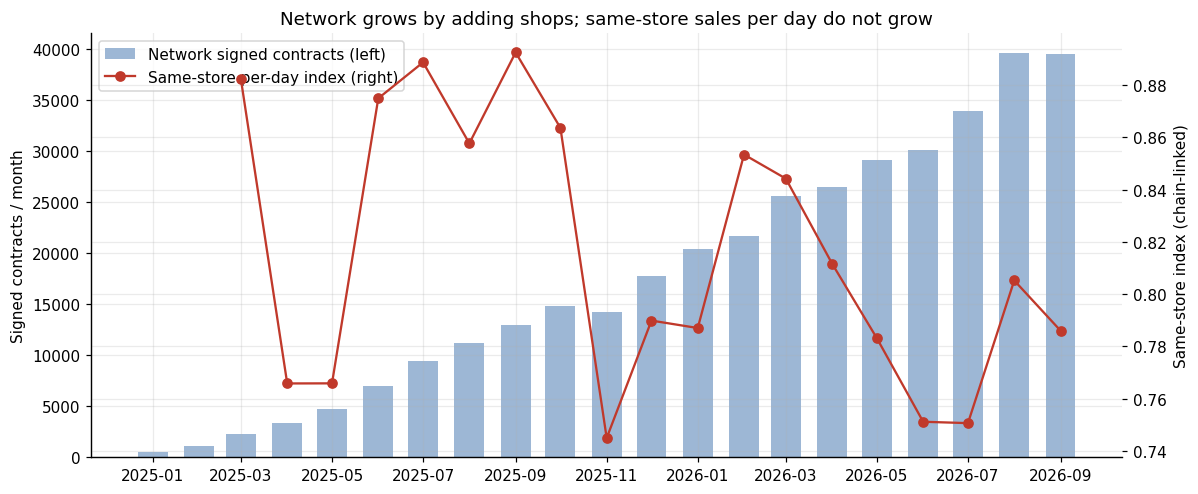

Same-store bình quân theo ngày: -1.26%/tháng (tháng có ≥100 shop so sánh)


In [12]:
def same_store_links(df, metric, min_age=1, min_panel=1):
    """Tỷ số tháng này/tháng trước THEO NGÀY, chỉ trên shop có đủ cả hai tháng đầy đủ (age ≥ min_age)."""
    g = df.groupby("shop_id", sort=False)
    d = df.assign(prev_y=g[metric].shift(1), prev_age=g["age"].shift(1), prev_dim=g["dim"].shift(1))
    d = d.loc[d["prev_age"].ge(min_age) & d["age"].ge(min_age)]
    link = (d.groupby("month")
              .agg(n_shops=("shop_id", "size"), y=(metric, "sum"), y_prev=("prev_y", "sum"),
                   dim=("dim", "first"), dim_prev=("prev_dim", "first"))
              .reset_index())
    link = link.loc[link["n_shops"].ge(min_panel) & link["y"].gt(0) & link["y_prev"].gt(0)].copy()
    link["l"] = np.log((link["y"] / link["dim"]) / (link["y_prev"] / link["dim_prev"]))   # log MoM theo ngày
    link["moy"] = link["month"].dt.month
    link["year"] = link["month"].dt.year
    return link


ss = same_store_links(phys, "signed_contracts", min_age=1)
ss["same_store_index"] = np.exp(ss["l"].cumsum())
ss_mu = ss.loc[ss["n_shops"].ge(CFG["SEASON_MIN_PANEL"]), "l"].mean()

fig, ax1 = plt.subplots(figsize=(11, 4.6))
ax1.bar(net.index, net["signed"], width=20, color="#9db7d5", label="Network signed contracts (left)")
ax1.set_ylabel("Signed contracts / month")
ax2 = ax1.twinx()
ax2.plot(ss["month"], ss["same_store_index"], color="#c0392b", marker="o", label="Same-store per-day index (right)")
ax2.set_ylabel("Same-store index (chain-linked)")
ax1.set_title("Network grows by adding shops; same-store sales per day do not grow")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()
print(f"Same-store bình quân theo ngày: {np.expm1(ss_mu):+.2%}/tháng "
      f"(tháng có ≥{CFG['SEASON_MIN_PANEL']} shop so sánh)")

**Phân tích kết quả GĐ3.2**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Cột tổng mạng lưới tăng đều mỗi tháng, trong khi chỉ số same-store **đi ngang đến giảm**: bình quân **−1,26%/tháng** theo ngày.
- **[Tin cậy Cao · Giá trị TB]** Chỉ số có những cú rơi rõ ở **11/2025** và đầu mùa hè 2026 (04–06/2026). Các tháng đó mạng lưới vẫn tăng nhờ shop mới.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Nhìn **tổng** mạng lưới sẽ thấy "mọi tháng đều tăng". Nhìn **same-store** mới thấy sức bán của shop hiện hữu đang mòn dần. BAU phải dựa trên góc nhìn thứ hai.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **Giả thuyết (kiểm ở 3.3):** −1,26%/tháng chủ yếu là **vòng đời**, vì nhiều shop trẻ đang giảm từ đỉnh khai trương, hơn là do thị trường xấu đi.
- **Câu hỏi (kiểm ở 4.4):** cú rơi 11/2025 là mùa vụ hay cú sốc?

### GĐ3.3 · Đường vòng đời shop (đo trong cùng shop)
**Mục đích:** kiểm chứng giả thuyết H2 "shop mới tăng tốc dần" (Q2). Nếu sai, BAU của 31% shop non tuổi sẽ lệch.

**Cách làm:**
1. Lấy các shop có **đủ 12 tháng đầy đủ**, để mọi tuổi đều có cùng một tập shop và tránh sai lệch thành phần.
2. Chia doanh số từng tháng tuổi cho trung bình 12 tháng **của chính shop đó** (loại khác biệt shop to/nhỏ); tính trung bình và khoảng tin cậy 95% theo tuổi.
3. Khớp hàm suy giảm hàm mũ f(a) = 1 + amp·e^(−(a−1)/τ) (quy về mức ổn định f(∞) = 1) bằng `curve_fit` có trọng số.
4. Ước lượng lại tại 4 thời điểm gốc, chỉ dùng dữ liệu đến thời điểm đó, để kiểm tra độ ổn định.

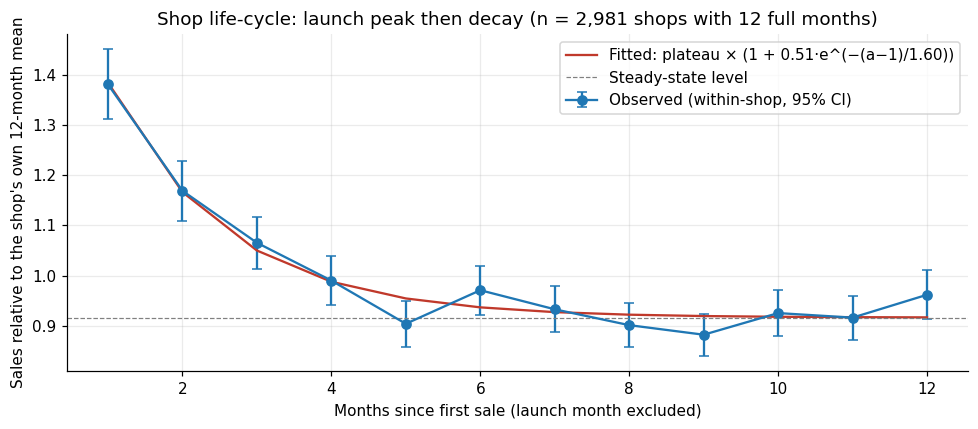

age,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000,11.0000,12.0000
mean,1.3814,1.1692,1.0655,0.9901,0.9039,0.9708,0.9328,0.9011,0.8821,0.9252,0.9162,0.9618
lo,1.3117,1.1089,1.0135,0.9404,0.8581,0.9219,0.8868,0.8572,0.8398,0.8800,0.8721,0.9133
hi,1.4512,1.2295,1.1176,1.0397,0.9497,1.0197,0.9787,0.9451,0.9243,0.9704,0.9602,1.0103
size,"2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000","2,981.0000"


,K,n_shops,amp,tau
origin,,,,
2025-12,10,237,0.4717,1.1918
2026-03,12,524,0.5293,0.9984
2026-06,12,1760,0.5015,2.1356
2026-09,12,3169,0.5113,1.5963


Hệ số vòng đời f(tuổi): {1: 1.511, 2: 1.273, 3: 1.146, 4: 1.078, 5: 1.042, 6: 1.022, 7: 1.012, 8: 1.006}


In [13]:
life = phys.loc[phys["age"].between(1, 12)].copy()
life = life.loc[life.groupby("shop_id")["age"].transform("size").eq(12)]
life["rel"] = life["signed_contracts"] / life.groupby("shop_id")["signed_contracts"].transform("mean")
life = life.loc[np.isfinite(life["rel"])]
life_curve = (life.groupby("age")["rel"].agg(["mean", "std", "size"])
                  .assign(se=lambda d: d["std"] / np.sqrt(d["size"]),
                          lo=lambda d: d["mean"] - 1.96 * d["se"], hi=lambda d: d["mean"] + 1.96 * d["se"]))


def estimate_lifecycle(df, origin, max_age=12, min_shops=150):
    """Đường vòng đời f(a) = 1 + amp·exp(−(a−1)/τ), f(∞) = 1. Chỉ dùng dữ liệu ≤ origin."""
    d = df.loc[df["month"].le(origin) & df["age"].between(1, max_age)]
    for K in range(max_age, 3, -1):           # K lớn nhất có đủ shop quan sát trọn K tháng
        dk = d.loc[d["age"].le(K)]
        dk = dk.loc[dk.groupby("shop_id")["age"].transform("size").eq(K)]
        if dk["shop_id"].nunique() >= min_shops:
            break
    rel = dk["signed_contracts"] / dk.groupby("shop_id")["signed_contracts"].transform("mean")
    prof = rel[np.isfinite(rel)].groupby(dk["age"]).agg(["mean", "size"])

    def fn(a, p, amp, tau):
        return p * (1 + amp * np.exp(-(a - 1) / tau))

    (p, amp, tau), _ = curve_fit(fn, prof.index.to_numpy(float), prof["mean"].to_numpy(),
                                 p0=[0.9, 0.5, 2.0], sigma=1 / np.sqrt(prof["size"].to_numpy()),
                                 bounds=([0.1, -0.9, 0.2], [3, 5, 24]))
    return {"origin": origin, "K": K, "n_shops": int(dk["shop_id"].nunique()), "plateau": p, "amp": amp,
            "tau": tau, "f": lambda a: 1 + amp * np.exp(-(np.asarray(a, dtype=float) - 1) / tau)}


LIFE_MAIN = estimate_lifecycle(phys, CFG["LAST_ACTUAL"])
ages = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(life_curve.index, life_curve["mean"], yerr=1.96 * life_curve["se"], marker="o", capsize=3,
            label="Observed (within-shop, 95% CI)")
ax.plot(ages, LIFE_MAIN["plateau"] * LIFE_MAIN["f"](ages), color="#c0392b",
        label=f"Fitted: plateau × (1 + {LIFE_MAIN['amp']:.2f}·e^(−(a−1)/{LIFE_MAIN['tau']:.2f}))")
ax.axhline(LIFE_MAIN["plateau"], color="grey", ls="--", lw=0.8, label="Steady-state level")
ax.set_xlabel("Months since first sale (launch month excluded)")
ax.set_ylabel("Sales relative to the shop's own 12-month mean")
ax.set_title(f"Shop life-cycle: launch peak then decay (n = {life['shop_id'].nunique():,} shops with 12 full months)")
ax.legend(); plt.tight_layout(); plt.show()
display(life_curve[["mean", "lo", "hi", "size"]].T)
life_stab = pd.DataFrame([{k: v for k, v in estimate_lifecycle(phys, T).items() if k in ("K", "n_shops", "amp", "tau")}
                          | {"origin": T.strftime("%Y-%m")}
                          for T in pd.to_datetime(["2025-12-01", "2026-03-01", "2026-06-01", "2026-09-01"])])
display(life_stab.set_index("origin"))
print("Hệ số vòng đời f(tuổi):", {a: round(float(LIFE_MAIN["f"](a)), 3) for a in range(1, 9)})

**Phân tích kết quả GĐ3.3**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Trên 2.981 shop đủ 12 tháng: tháng đầy đủ thứ 1 đạt **1,38×** TB của chính shop (khoảng tin cậy 95%: 1,31–1,45), tháng 2 đạt **1,17×**, tháng 3 đạt **1,07×**; từ tháng 5 trở đi dao động **0,88–0,97×**. Khoảng tin cậy của tháng 1–3 không chạm vùng ổn định.
- **[Tin cậy Cao · Giá trị Cao]** Hàm khớp: **amp = 0,51, τ = 1,60 tháng**, tức tháng 1 cao hơn mức ổn định +51%, tháng 3 còn +15%, tháng 6 còn +2%.
- **[Tin cậy Cao · Giá trị TB]** Đường cong **ổn định** khi ước lượng tại 4 thời điểm gốc khác nhau: amp 0,47–0,53, τ 1,0–2,1.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** **Bác bỏ H2.** Shop mới **không** tăng tốc dần mà có **"đỉnh khai trương"** rồi giảm về mức ổn định sau khoảng 4–6 tháng. Nguyên nhân có thể là khuyến mại khai trương, lượng khách tò mò ban đầu, và SA được đẩy chỉ tiêu lúc mới mở.
- **[Tin cậy Cao · Giá trị Cao]** Hệ quả cho BAU: shop 1–3 tháng tuổi **chắc chắn còn giảm**. Lấy mức hiện tại làm BAU sẽ thổi phồng BAU của shop mới; GĐ9 xác nhận thiếu vòng đời thì BAU lệch +7,0%. Đường vòng đời là **thành phần bắt buộc**.
- **[Tin cậy TB · Giá trị TB]** Kết hợp với 3.2: phần lớn mức −1,26%/tháng của same-store là **vòng đời**, không phải thị trường xấu đi.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 3 (benchmark):** không so shop 1–3 tháng tuổi với shop ổn định bằng số thô. Hoặc quy đổi theo f(tuổi), hoặc tách peer group "shop mới" (Bước 1 cũng đã khuyến nghị).
- **→ Bước 5 (nguyên nhân gap):** "đỉnh khai trương rồi giảm" có thể là một vấn đề **Execution**: duy trì được 50% đỉnh khai trương là một can thiệp có giá trị.
- **Đề xuất bổ sung:** kiểm tra đường vòng đời riêng theo ngành (CD/TW/NS) khi có thêm dữ liệu. Hiện tại dùng đường chung để tránh overfitting.

### GĐ3.4 · Đo nhiễu và ngưỡng trend phát hiện được
**Mục đích:** kiểm chứng H3 "trend 6 tháng của shop nhỏ chủ yếu là nhiễu" (Q3). Nếu đúng, việc "kéo dài trend" theo nghĩa đen là kéo dài nhiễu.

**Cách làm:**
1. Lấy shop có đủ 6 tháng đầy đủ (04–09/2026), chia theo quy mô bán.
2. Tính φ = phương sai/trung bình (với số đếm thuần ngẫu nhiên kiểu Poisson thì φ ≈ 1) và hệ số biến thiên CV.
3. Tính ngưỡng trend nhỏ nhất phát hiện được ở mức 95%: 1,96·√(φ/(17,5·mức nền)), trong đó 17,5 = Σ(t − t̄)² với 6 điểm.

In [14]:
win6 = phys.loc[phys["month"].gt(CFG["LAST_ACTUAL"] - pd.DateOffset(months=6)) & phys["valid"]]
w6 = win6.groupby("shop_id")["signed_contracts"].agg(["mean", "var", "size"])
w6 = w6.loc[w6["size"].eq(6) & w6["mean"].gt(0)]
size_bins = [0, 1, 3, 10, 30, np.inf]
size_labels = ["≤1", "1–3", "3–10", "10–30", ">30"]
w6["size_band"] = pd.cut(w6["mean"], size_bins, labels=size_labels)
w6 = w6.assign(phi=w6["var"] / w6["mean"], cv=np.sqrt(w6["var"]) / w6["mean"])
noise = w6.groupby("size_band", observed=True).agg(shops=("mean", "size"), mean_level=("mean", "median"),
                                                   var_over_mean=("phi", "median"), cv=("cv", "median"))
noise["min_detectable_trend_%/month"] = 1.96 * np.sqrt(noise["var_over_mean"].clip(lower=1)
                                                       / (17.5 * noise["mean_level"])) * 100
zero_share = (panel.loc[panel["valid"] & panel["is_physical"], "signed_contracts"] == 0).mean()
display(noise)
print(f"Tỷ lệ shop×tháng (tháng đầy đủ) có 0 contract: {zero_share:.1%}")

,shops,mean_level,var_over_mean,cv,min_detectable_trend_%/month
size_band,,,,,
≤1,1696,0.5000,1.0000,1.5492,66.2601
1–3,1441,1.8333,1.2000,0.8198,37.9059
3–10,1265,5.3333,1.5132,0.5345,24.9567
10–30,503,14.6667,1.7869,0.3422,16.3538
>30,90,43.1667,2.4776,0.2356,11.2248


Tỷ lệ shop×tháng (tháng đầy đủ) có 0 contract: 38.5%


**Phân tích kết quả GĐ3.4**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** **38,5%** shop×tháng (tháng đầy đủ) có 0 contract.
- **[Tin cậy Cao · Giá trị Cao]** Shop ≤1 contract/tháng: φ = **1,0** (đúng Poisson), CV = **155%**. φ tăng dần theo quy mô (2,48 ở shop >30/tháng).
- **[Tin cậy Cao · Giá trị Cao]** Ngưỡng trend phát hiện được: **66%/tháng** (≤1/tháng) · 38% (1–3) · 25% (3–10) · 16% (10–30) · **11%** (>30).

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** **Xác nhận H3.** Với 1.696 shop ≤1 contract/tháng, biến động tháng-sang-tháng gần như hoàn toàn là **ngẫu nhiên**. Một shop tháng này 0, tháng sau 2 không có nghĩa là "đang tăng". "Kéo dài trend 6 tháng" cho các shop này là kéo dài nhiễu. Vì vậy GĐ5 bắt buộc có kiểm định và lọc nhiễu, và GĐ6 phải đo xem trend kéo dài được bao nhiêu.
- **[Tin cậy Cao · Giá trị TB]** Shop lớn có φ > 1: biến động thật lớn hơn ngẫu nhiên (khuyến mại, nhân sự, nguồn hàng), nên trend của họ **đáng đọc hơn**.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 7 (nhãn tin cậy):** ngưỡng ở bảng trên là căn cứ định lượng cho nhãn "doanh số lên xuống thất thường, mỗi tháng 1–2 contract → tin cậy thấp".
- **→ Bước 3:** KPI tỷ lệ (approval, conversion) của shop nhỏ cũng nhiễu như vậy, nên cân nhắc ngưỡng mẫu tối thiểu khi so với benchmark.

### GĐ3.5 · Mức độ tập trung doanh số
**Mục đích:** biết độ chính xác của BAU quan trọng nhất ở nhóm shop nào.

**Cách làm:** xếp shop theo contract CA (07–09/2026), tính tỷ trọng của top 1%, 10%, 20%, 50%.

In [15]:
ca_shop = phys.loc[phys["month"].ge(CFG["CA_START"])].groupby("shop_id")["signed_contracts"].sum()
ca_sorted = ca_shop.sort_values(ascending=False)
conc = pd.Series({f"Top {int(q * 100)}% shop": ca_sorted.head(int(len(ca_sorted) * q)).sum() / ca_sorted.sum()
                  for q in (0.01, 0.10, 0.20, 0.50)}).rename("tỷ trọng contract CA")
display(conc.to_frame())

,tỷ trọng contract CA
Top 1% shop,0.2078
Top 10% shop,0.6194
Top 20% shop,0.7990
Top 50% shop,0.9795


**Phân tích kết quả GĐ3.5**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Top 1% shop = **20,8%** contract; top 10% = **61,9%**; top 20% = **79,9%**; top 50% = 98,0%.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Mạng lưới kiểu "đuôi dài": nửa dưới số shop chỉ chiếm 2% doanh số. Độ chính xác của BAU quyết định ở **khoảng 20% shop lớn**, và đây cũng là nhóm có trend đo được (3.4). Kết hợp hai phát hiện: tin trend riêng ở shop lớn, kéo shop nhỏ về mức chung (GĐ5.5).

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 6:** với nguồn lực có hạn, opportunity gap tính bằng **tổng** contract sẽ tự nhiên dồn về nhóm top 20%. Cần quyết định có xếp hạng theo gap tuyệt đối hay gap tương đối.

---
## GĐ4 · Lịch & mùa vụ (seasonality)

**Mục đích giai đoạn:** tính seasonality từ dữ liệu năm 2025, với hai điều kiện: (a) không bị méo bởi việc mở shop (số shop tăng 80 lần), (b) chỉ giữ phần mùa vụ **có bằng chứng lặp lại**.

**Phương pháp tổng thể:** tỷ số same-store theo ngày (4.1) → chỉ số mùa vụ theo phương pháp link relatives của Persons (4.2) → kiểm định lặp lại 2025 so với 2026 và co hệ số (4.3) → mổ xẻ cú sốc 11/2025 (4.4) → mùa vụ theo ngành quanh Tết (4.5) → hệ số tháng cuối cùng (4.6).

### GĐ4.1–4.3 · Chỉ số mùa vụ và kiểm định lặp lại
**Mục đích:** ước lượng mùa vụ từ dữ liệu ≤ thời điểm gốc, và đo **mức tin** B ∈ [0, 1] bằng chính dữ liệu.

**Cách làm:**
1. **(4.1)** Tỷ số same-store theo ngày l(t) (hàm ở GĐ3.2); bỏ tháng có < 100 shop so sánh được.
2. **(4.2)** Trung bình l theo tháng-trong-năm → trừ trôi chung μ → cộng dồn → chuẩn hóa tổng = 0 → chỉ số thô s(m) (phương pháp link relatives của Persons).
3. **(4.3)** Với các tháng có cả 2025 và 2026: phương sai nhiễu σ² = TB(chênh lệch²)/2; phương sai mùa vụ thật τ² = Var(chỉ số) − σ²/n; **B = τ²/(τ² + σ²/n)** (Empirical Bayes). Mùa vụ dùng = B·s(m).
4. Hàm nhận tham số `origin`, để mọi kiểm tra về sau không dùng dữ liệu tương lai.

moy,1,2,3,4,5,6,7,8,9,10,11,12
log-link TB,-0.0036,0.0810,-0.0681,-0.0904,-0.0179,0.0458,0.0075,0.0173,0.0078,-0.0329,-0.1479,0.0586
số năm quan sát,1.0000,1.0000,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000,1.0000,1.0000,1.0000
chỉ số thô exp(s),0.9846,1.0805,1.0214,0.9443,0.9387,0.9944,1.0138,1.0439,1.0647,1.0426,0.9100,0.9765
chỉ số dùng exp(B·s),0.9973,1.0136,1.0037,0.9901,0.9890,0.9990,1.0024,1.0075,1.0110,1.0073,0.9837,0.9959


Trôi same-store μ = -1.18%/tháng | σ nhiễu = 0.071 | τ² = 0.00067 | tương quan 2025–2026 = -0.15 | B = 0.17


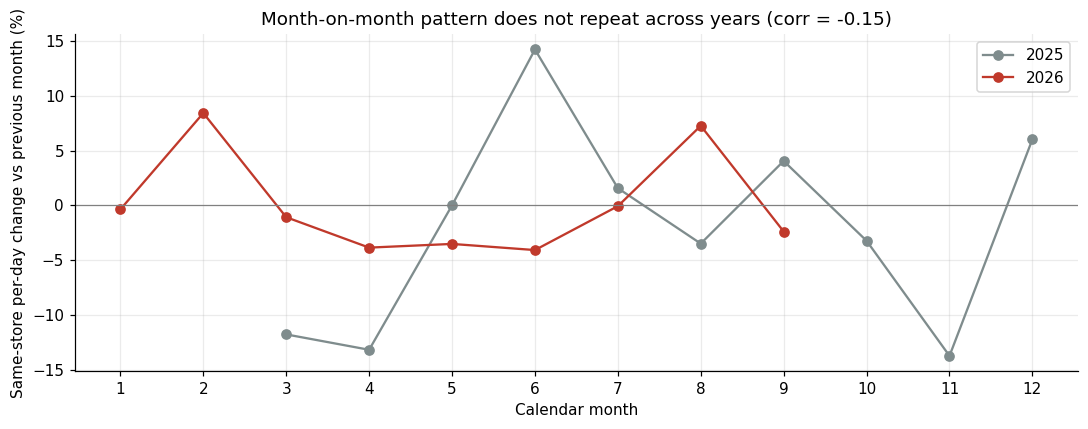

In [16]:
def estimate_season(df, origin, metric="signed_contracts", shrink=None, min_age=1,
                    min_panel=CFG["SEASON_MIN_PANEL"]):
    """Mùa vụ same-store theo ngày, chỉ dùng dữ liệu ≤ origin. shrink=None → B ước lượng từ dữ liệu (EB)."""
    link = same_store_links(df.loc[df["month"].le(origin)], metric, min_age, min_panel)
    lr = link.groupby("moy")["l"].mean().reindex(range(1, 13))
    n_obs = link.groupby("moy")["l"].size().reindex(range(1, 13)).fillna(0)
    mu = lr.mean()
    s_raw = (lr - mu).fillna(0).cumsum()
    s_raw = s_raw - s_raw.mean()
    rep = link.pivot_table(index="moy", columns="year", values="l").dropna()     # tháng có ≥ 2 năm
    sigma2, corr = np.nan, np.nan
    if rep.shape[0] >= 3 and rep.shape[1] >= 2:
        diff = rep.iloc[:, -1] - rep.iloc[:, -2]
        sigma2 = float((diff ** 2).mean() / 2)                                   # Var(nhiễu) 1 quan sát
        corr = float(np.corrcoef(rep.iloc[:, -2], rep.iloc[:, -1])[0, 1])
    obs = n_obs[n_obs > 0]
    if np.isfinite(sigma2):
        tau2 = max(float(lr.dropna().var(ddof=1)) - float((sigma2 / obs).mean()), 0.0)
        B_eb = tau2 / (tau2 + sigma2 / float(obs.mean()))
    else:
        tau2, B_eb = np.nan, 0.0                     # chưa có bằng chứng lặp lại → không dùng mùa vụ
    B = B_eb if shrink is None else float(shrink)
    s_used = B * s_raw
    return {"origin": origin, "link": link, "lr": lr, "n_obs": n_obs, "mu": mu, "s_raw": s_raw,
            "sigma2": sigma2, "tau2": tau2, "corr_years": corr, "B": B, "s_used": s_used - s_used.mean()}


def season_factor(months, season):
    """S_m = (số ngày / 30,44) × exp(B·s_m)."""
    months = pd.DatetimeIndex(months)
    days = np.ones(len(months)) if season.get("no_days") else months.days_in_month / MEAN_DAYS
    return np.asarray(days) * np.exp(season["s_used"].reindex(months.month).to_numpy())


season_main = estimate_season(phys, CFG["LAST_ACTUAL"])
display(pd.DataFrame({"log-link TB": season_main["lr"], "số năm quan sát": season_main["n_obs"].astype(int),
                      "chỉ số thô exp(s)": np.exp(season_main["s_raw"]),
                      "chỉ số dùng exp(B·s)": np.exp(season_main["s_used"])}).T)
print(f"Trôi same-store μ = {np.expm1(season_main['mu']):+.2%}/tháng | σ nhiễu = {np.sqrt(season_main['sigma2']):.3f} | "
      f"τ² = {season_main['tau2']:.5f} | tương quan 2025–2026 = {season_main['corr_years']:+.2f} | B = {season_main['B']:.2f}")
wide = season_main["link"].pivot_table(index="moy", columns="year", values="l")
fig, ax = plt.subplots(figsize=(10, 4))
for yr, col in zip(wide.columns, ["#7f8c8d", "#c0392b"]):
    ax.plot(wide.index, np.expm1(wide[yr]) * 100, marker="o", label=str(yr), color=col)
ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(range(1, 13))
ax.set_xlabel("Calendar month"); ax.set_ylabel("Same-store per-day change vs previous month (%)")
ax.set_title(f"Month-on-month pattern does not repeat across years (corr = {season_main['corr_years']:+.2f})")
ax.legend(); plt.tight_layout(); plt.show()

**Phân tích kết quả GĐ4.1–4.3**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Ở **7 tháng** quan sát được cả 2025 và 2026 (03 → 09), biến động tháng-sang-tháng **không lặp lại**: tương quan giữa hai năm = **−0,15**. Ví dụ: tháng 6 là +14,2% năm 2025 nhưng −4,1% năm 2026; tháng 8 là −3,5% năm 2025 nhưng +7,3% năm 2026.
- **[Tin cậy Cao · Giá trị Cao]** Nhiễu của một quan sát σ = 0,071, lớn hơn hẳn phần mùa vụ thật (τ² = 0,00067), nên **B = 0,17**.
- **[Tin cậy TB · Giá trị TB]** Chỉ số thô (chưa co) cho 6 tháng dự báo: 10 = 1,043 · **11 = 0,910** · 12 = 0,977 · 01 = 0,985 · 02 = 1,081 · 03 = 1,021. Riêng các tháng 10 → 02 chỉ có **một** quan sát.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Sau khi bỏ hiệu ứng số ngày, mùa vụ theo tháng của mạng lưới **gần như là nhiễu**. BAU chỉ dùng 17% biên độ mùa vụ ước lượng được. Đây là câu trả lời trung thực cho yêu cầu "lấy mùa vụ từ 2025": *đã lấy, đã kiểm định, và chỉ giữ phần có bằng chứng*.
- **[Tin cậy TB · Giá trị TB]** Năm 2025 mạng lưới còn nhỏ (100–2.000 shop so sánh được) và toàn shop non tuổi, nên mùa vụ 2025 bị lẫn với vòng đời. Đây là một lý do nữa để không tin hoàn toàn vào chỉ số thô.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 7 (sensitivity):** thử B = 0 và B = 1 bằng tham số `shrink`. Kết quả BAU trung bình 6 tháng chỉ đổi khoảng +1% / −4%.
- **Đề xuất bổ sung:** khi có đủ năm 2026, ước lượng lại B (thêm 3 tháng 10–12 có 2 năm quan sát).

### GĐ4.4–4.5 · Mổ xẻ cú sốc 11/2025 và mùa vụ theo ngành quanh Tết
**Mục đích:**
- (4.4) Chỉ số thô tháng 11 = 0,910 dựa trên **một** quan sát. Cần biết đây là mùa vụ hay cú sốc trước khi áp vào 11/2026.
- (4.5) Kiểm tra liệu mùa vụ chung yếu có phải do các ngành **triệt tiêu nhau** hay không.

**Cách làm:** tính tỷ số same-store theo ngày từ 10/2025 đến 03/2026 riêng cho từng ngành (CD/NS/TW); tính tháng 11/2025 riêng cho từng vùng kinh doanh. Giả thuyết đối chứng: nếu là thời tiết (lũ miền Trung) thì phải giảm cả TW và tập trung ở miền Trung.

In [17]:
by_prod = {}
for prod in ["CD", "NS", "TW"]:
    lk = same_store_links(phys.loc[phys["SALESROOM_PRODUCT"].eq(prod)], "signed_contracts", 1, 30)
    by_prod[prod] = lk.set_index("month")["l"]
by_prod = pd.DataFrame(by_prod)
focus = by_prod.loc[by_prod.index.isin(pd.date_range("2025-10-01", "2026-03-01", freq="MS"))]
display(np.expm1(focus).rename(index=lambda d: d.strftime("%Y-%m")).rename(columns=lambda c: f"{c}: per-day MoM"))

area_rows = []
for area, sub in phys.groupby("salesroom_area"):
    lk = same_store_links(sub, "signed_contracts", 1, 1)
    hit = lk.loc[lk["month"].eq("2025-11-01")]
    if len(hit):
        area_rows.append((area, float(np.expm1(hit["l"].iloc[0])), int(hit["n_shops"].iloc[0])))
display(pd.DataFrame(area_rows, columns=["area", "11/2025 per-day change", "shops"])
        .sort_values("11/2025 per-day change").set_index("area"))

,CD: per-day MoM,NS: per-day MoM,TW: per-day MoM
month,,,
2025-10,-0.0404,-0.1340,0.1023
2025-11,-0.1804,-0.1936,0.0243
2025-12,0.0251,-0.0502,0.2076
2026-01,0.0999,0.0129,-0.1951
2026-02,0.1946,-0.0395,-0.1074
2026-03,-0.1995,0.1714,0.5007


,11/2025 per-day change,shops
area,,
Eastern North,-0.2460,197
North East,-0.2235,499
Central - NHL,-0.1879,304
North West,-0.1648,236
North,-0.1590,577
Sai Gon,-0.1317,402
Western,-0.1257,335
Eastern South,-0.0260,193
Mekong,-0.0026,187


**Phân tích kết quả GĐ4.4–4.5**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** 11/2025 theo ngành: CD **−18%**, NS **−19%**, TW **+2%**.
- **[Tin cậy Cao · Giá trị TB]** 11/2025 theo vùng: giảm mạnh nhất ở miền Bắc (Eastern North −25%, North East −22%, North −16%), Central −19%; Mekong 0%, South East **+4%**.
- **[Tin cậy TB · Giá trị Cao]** Quanh Tết (Tết rơi vào 17/02/2026): CD **+19%** trong 02/2026 rồi **−20%** trong 03/2026; TW **+21%** trong 12/2025, −20% trong 01/2026, −11% trong 02/2026, rồi **+50%** trong 03/2026.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Cú giảm 11/2025 là **cú sốc riêng của ngành CD/NS**, không phải mùa vụ, và khó giải thích bằng thời tiết: TW không giảm, và miền Bắc giảm mạnh hơn miền Trung. Nếu đưa nguyên vào mùa vụ, BAU 11/2026 bị hạ 9% vô căn cứ. Cơ chế co B (4.3) đã hạ mức này xuống còn 1,6%.
- **[Tin cậy TB · Giá trị Cao]** **Tết tác động ngược chiều:** khách mua **điện thoại, điện máy ngay trước Tết**, còn **xe máy** được mua cuối năm (tháng 12) rồi bật lại mạnh **sau Tết** (tháng 3). Gộp chung toàn mạng lưới thì hai chiều này triệt tiêu nhau. Đây là lý do mùa vụ chung trông yếu.
- **[Tin cậy TB · Giá trị TB]** Mới quan sát được **một** mùa Tết, nên nhóm **không** đưa hệ số Tết theo ngành vào số BAU (tránh overfitting). Tết 2027 rơi vào **06/02/2027**, sớm hơn khoảng 11 ngày, nên phần mua sắm trước Tết sẽ dịch sang 01/2027. Điều này chỉ làm phân bổ giữa tháng 1 và tháng 2 bất định, **không** ảnh hưởng BAU trung bình 6 tháng.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **Câu hỏi cho Sales/BTC:** điều gì xảy ra với CD/NS trong 11/2025 (kết thúc chương trình 0%, thay đổi chính sách duyệt, nguồn hàng, hay nhu cầu dồn vào 10/2025 do ra mắt sản phẩm mới)?
- **→ Bước 6 (lộ trình triển khai):** nên chọn thời điểm can thiệp theo ngành. Ví dụ dồn lead/SA cho shop CD vào 01–02, cho shop TW vào 12 và 03. Đây là gợi ý; Bước 6 quyết định.
- **Đề xuất bổ sung:** khi có thêm một mùa Tết, ước lượng mùa vụ theo ngành và căn theo ngày Tết (âm lịch) thay vì theo tháng dương lịch.

### GĐ4.6 · Hệ số tháng cuối cùng cho 6 tháng dự báo
**Mục đích:** có một hệ số S(m) cho mỗi tháng dự báo.

**Cách làm:** S(m) = (số ngày/30,44) × e^(B·s(m)), với B = 0,17.

In [18]:
fc_factors = pd.DataFrame({
    "month": FC_MONTHS.strftime("%Y-%m"), "số ngày": FC_MONTHS.days_in_month,
    "hệ số ngày": FC_MONTHS.days_in_month / MEAN_DAYS,
    "mùa vụ thô exp(s)": np.exp(season_main["s_raw"].reindex(FC_MONTHS.month).to_numpy()),
    "mùa vụ dùng exp(B·s)": np.exp(season_main["s_used"].reindex(FC_MONTHS.month).to_numpy()),
})
fc_factors["S_m (cuối cùng)"] = season_factor(FC_MONTHS, season_main)
display(fc_factors.set_index("month"))

,số ngày,hệ số ngày,mùa vụ thô exp(s),mùa vụ dùng exp(B·s),S_m (cuối cùng)
month,,,,,
2026-10,31,1.0185,1.0426,1.0073,1.0259
2026-11,30,0.9856,0.9100,0.9837,0.9696
2026-12,31,1.0185,0.9765,0.9959,1.0143
2027-01,31,1.0185,0.9846,0.9973,1.0157
2027-02,28,0.9199,1.0805,1.0136,0.9324
2027-03,31,1.0185,1.0214,1.0037,1.0222


**Phân tích kết quả GĐ4.6**

**① Pattern**
- **[Tin cậy Cao · Giá trị TB]** S(m): 10/2026 = 1,026 · 11 = 0,970 · 12 = 1,014 · 01/2027 = 1,016 · **02 = 0,932** · 03 = 1,022. Mùa vụ sau khi co chỉ còn dao động ±1,6%; phần còn lại là số ngày.

**② Insight**
- **[Tin cậy Cao · Giá trị TB]** Tháng 2 và tháng 11 thấp hơn chủ yếu vì **ít ngày**. BAU tháng 2 thấp **không** có nghĩa là shop yếu đi.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ GĐ5–GĐ7:** S(m) được dùng hai lần: khử mùa vụ lịch sử trước khi đo trend, và nhân lại khi dự báo.

---
## GĐ5 · Trend 6 tháng của từng shop: ước lượng, kiểm định, phân loại, lọc nhiễu

**Mục đích giai đoạn:** xếp trend 6 tháng gần nhất của từng shop vào đi lên, đi xuống hay đứng yên, tính riêng từng shop, sao cho nhãn **có ý nghĩa thống kê** và trend đưa vào BAU **đã lọc nhiễu**.

**Phương pháp tổng thể:** chuỗi chuẩn hóa (bỏ số ngày, mùa vụ, vòng đời) → mức nền L và độ dốc OLS → sai số chuẩn theo mô hình đếm (φ) → kiểm định z → nhãn → lọc nhiễu Empirical Bayes (DerSimonian–Laird).

### GĐ5.1 · Hàm ước lượng mức nền, trend, kiểm định và lọc nhiễu
**Mục đích:** một hàm duy nhất, dùng lại được tại mọi thời điểm gốc (GĐ6, GĐ9, Bước 7).

**Cách làm (các bước bên trong hàm `level_trend`):**
1. Chuỗi chuẩn hóa y* = y / [S(t)·f(tuổi)], chỉ tháng đầy đủ trong cửa sổ 6 tháng. Bỏ vòng đời để đỉnh khai trương tự giảm của shop mới **không** bị đọc thành "đi xuống".
2. Mức nền L = TB y*; độ dốc β bằng OLS; trend tương đối g = β/L (%/tháng). L dùng TB **6 tháng** vì L trực giao với độ dốc OLS (tránh bẫy hồi quy về trung bình ở GĐ6).
3. φ (overdispersion) ước lượng từ phần dư OLS theo 5 nhóm quy mô; SE(g) = √(φ/(Sxx·L)).
4. z = g/SE: |z| > 1,96 → Đi lên/Đi xuống; còn lại → Đứng yên. Mức nền 0 với ≥3 tháng đầy đủ → Ngủ đông; dưới 4 tháng → Chưa đủ dữ liệu.
5. DerSimonian–Laird: τ² = độ phân tán **thật** giữa các shop; B_i = τ²/(τ² + SE²); g̃ = μ + B_i(g − μ), chặn ±15%/tháng.

In [19]:
def level_trend(df, origin, season, metric="signed_contracts", window=CFG["WINDOW"],
                min_valid=CFG["MIN_VALID_FOR_TREND"], cap=CFG["TREND_CAP"], min_month=None, life=None):
    """Mức nền, độ dốc, kiểm định và trend sau lọc nhiễu của từng shop tại `origin` (dữ liệu ≤ origin)."""
    start = origin - pd.DateOffset(months=window - 1)
    w = df.loc[df["month"].between(start, origin) & df["valid"]]
    if min_month is not None:
        w = w.loc[w["month"].ge(min_month)]
    w = w.assign(S=season_factor(w["month"], season),
                 t=month_diff(w["month"], pd.Series(origin, index=w.index)).astype(float),
                 LF=life["f"](w["age"]) if life else 1.0)
    w = w.assign(ys=w[metric] / (w["S"] * w["LF"]))                       # (1) chuỗi chuẩn hóa
    a = w.groupby("shop_id").agg(n_valid=("t", "size"), t_bar=("t", "mean"), level=("ys", "mean"),
                                 raw_mean=(metric, "mean"))
    a["age_origin"] = (w["age"] - w["t"]).groupby(w["shop_id"]).max()
    w = w.join(a[["t_bar", "level"]], on="shop_id")
    dt, dy = w["t"] - w["t_bar"], w["ys"] - w["level"]
    sums = (pd.DataFrame({"shop_id": w["shop_id"], "sxy": dt * dy, "sxx": dt ** 2, "syy": dy ** 2})
              .groupby("shop_id")[["sxy", "sxx", "syy"]].sum())
    a = a.join(sums)
    a["beta"] = a["sxy"] / a["sxx"].replace(0, np.nan)                    # (2) OLS
    a["g_raw"] = a["beta"] / a["level"].replace(0, np.nan)
    a["rss"] = (a["syy"] - a["sxy"] ** 2 / a["sxx"].replace(0, np.nan)).clip(lower=0)
    a["size_band"] = pd.cut(a["raw_mean"], size_bins, labels=size_labels, include_lowest=True)
    est = a.loc[a["n_valid"].ge(min_valid) & a["level"].gt(0)]
    num = est.groupby("size_band", observed=True)["rss"].sum()           # (3) φ theo quy mô
    den = ((est["n_valid"] - 2) * est["level"]).groupby(est["size_band"], observed=True).sum()
    phi = (num / den.replace(0, np.nan)).astype(float)
    a["phi"] = a["size_band"].astype(object).map(phi.to_dict()).astype(float).fillna(1.0).clip(lower=1.0)
    a["se2"] = a["phi"] / (a["sxx"] * a["level"]).replace(0, np.nan)
    ok = a["n_valid"].ge(min_valid) & a["level"].gt(0) & np.isfinite(a["g_raw"]) & np.isfinite(a["se2"])
    wts = 1 / a.loc[ok, "se2"]                                            # (5) DerSimonian–Laird
    mu = float((wts * a.loc[ok, "g_raw"]).sum() / wts.sum())
    Q = float((wts * (a.loc[ok, "g_raw"] - mu) ** 2).sum())
    k = int(ok.sum())
    tau2 = max(0.0, (Q - (k - 1)) / (wts.sum() - (wts ** 2).sum() / wts.sum())) if k > 1 else 0.0
    a["B_shrink"] = np.where(ok, tau2 / (tau2 + a["se2"]), 0.0)
    a["g_shrunk"] = np.clip(np.where(ok, mu + a["B_shrink"] * (a["g_raw"] - mu), 0.0), -cap, cap)
    a["z"] = np.where(ok, a["g_raw"] / np.sqrt(a["se2"]), np.nan)          # (4) kiểm định & nhãn
    a["trend_label"] = np.select(
        [a["level"].le(0) & a["n_valid"].ge(3), ~ok, a["z"].gt(1.96), a["z"].lt(-1.96)],
        ["Ngủ đông (0 contract)", "Chưa đủ dữ liệu", "Đi lên", "Đi xuống"], default="Đứng yên")
    a.attrs.update({"mu": mu, "tau2": tau2, "Q_over_df": Q / max(k - 1, 1), "k": k, "phi": phi.to_dict()})
    return a


lt_main = level_trend(phys, CFG["LAST_ACTUAL"], season_main, life=LIFE_MAIN)
print(f"Shop có mức nền: {len(lt_main):,} | đủ điều kiện ước lượng trend (≥4 tháng, L>0): {lt_main.attrs['k']:,}")

Shop có mức nền: 9,084 | đủ điều kiện ước lượng trend (≥4 tháng, L>0): 6,024


### GĐ5.2–5.3 · Phân phối mức nền, trend thô và nhiễu φ
**Mục đích:** nhìn quy mô và độ dốc thực tế của các shop trước khi gắn nhãn; xem φ ước lượng từ dữ liệu.

**Cách làm:** phân vị của L và g; bảng φ theo nhóm quy mô.

**Hậu kiểm định:** φ ≥ 1 ở mọi nhóm; số shop đủ điều kiện ≤ số shop có mức nền.

In [20]:
elig = lt_main.loc[lt_main["n_valid"].ge(CFG["MIN_VALID_FOR_TREND"]) & lt_main["level"].gt(0)]
display(pd.DataFrame({"mức nền L (contract/tháng)": lt_main["level"].quantile([.1, .25, .5, .75, .9]),
                      "trend thô g (%/tháng)": elig["g_raw"].quantile([.1, .25, .5, .75, .9]),
                      "trend sau lọc g̃ (%/tháng)": elig["g_shrunk"].quantile([.1, .25, .5, .75, .9])})
        .rename(index=lambda q: f"P{int(q * 100)}"))
print("φ (phương sai/trung bình) theo quy mô:", {k: round(v, 2) for k, v in lt_main.attrs["phi"].items()})
assert all(v >= 1 for v in lt_main["phi"].dropna())

,mức nền L (contract/tháng),trend thô g (%/tháng),trend sau lọc g̃ (%/tháng)
P10,0.0000,-0.4326,-0.0719
P25,0.3224,-0.1714,-0.0252
P50,1.3264,0.0119,0.0156
P75,3.7985,0.1871,0.0590
P90,9.1920,0.4143,0.1105


φ (phương sai/trung bình) theo quy mô: {'≤1': 1.1, '1–3': 1.27, '3–10': 1.57, '10–30': 1.91, '>30': 4.29}


**Phân tích kết quả GĐ5.2–5.3**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Mức nền trung vị chỉ **1,3 contract/tháng**: P25 = 0,3; P75 = 3,8; P90 = 9,2.
- **[Tin cậy Cao · Giá trị Cao]** Trend thô dao động rất rộng: P10 = **−43%/tháng**, P90 = **+41%/tháng**. Sau khi lọc nhiễu chỉ còn P10 = −7%, P90 = +11%.
- **[Tin cậy Cao · Giá trị TB]** φ: ≤1/tháng = 1,10 · 1–3 = 1,27 · 3–10 = 1,57 · 10–30 = 1,91 · >30 = 4,29.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Trend ±40%/tháng ở shop bán 1–2 contract là **dao động ngẫu nhiên**, không phải động lực kinh doanh. Nếu kéo dài 6 tháng sẽ ra các con số vô lý: gấp ba lần hoặc gần như về 0.
- **[Tin cậy TB · Giá trị TB]** φ rất lớn ở shop >30/tháng cho thấy shop lớn chịu **cú sốc chung theo tháng** (khuyến mại, nhân sự, nguồn hàng). Vì vậy kể cả shop lớn cũng không nên tin trend 100%.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ GĐ6:** câu hỏi then chốt "trend sau lọc nhiễu kéo dài được bao nhiêu?" sẽ được đo trực tiếp trên lịch sử.

### GĐ5.4 · Nhãn trend: đi lên / đi xuống / đứng yên
**Mục đích:** phân loại từng shop bằng kiểm định thống kê (mức ý nghĩa 5%), không bằng cảm tính.

**Cách làm:** đếm nhãn; xem tỷ lệ shop có trend có ý nghĩa theo quy mô. Nếu chỉ có nhiễu thì tỷ lệ này khoảng 5%.

In [21]:
lab = (lt_main.groupby("trend_label")
              .agg(shops=("level", "size"), level_median=("level", "median"),
                   g_raw_median=("g_raw", "median"), g_shrunk_median=("g_shrunk", "median")))
lab["share"] = lab["shops"] / lab["shops"].sum()
display(lab)
shr = (elig.groupby("size_band", observed=True)
           .agg(shops=("level", "size"), median_SE=("se2", lambda s: float(np.sqrt(s).median())),
                median_B=("B_shrink", "median"),
                share_significant=("trend_label", lambda s: float(s.isin(["Đi lên", "Đi xuống"]).mean()))))
display(shr)
prof = (lt_main.loc[lt_main["trend_label"].isin(["Đi lên", "Đi xuống"])].join(shops[["shop_category", "SALESROOM_PRODUCT"]])
               .groupby(["trend_label", "SALESROOM_PRODUCT"]).size().unstack(fill_value=0))
display(prof)

,shops,level_median,g_raw_median,g_shrunk_median,share
trend_label,,,,,
Chưa đủ dữ liệu,1874,1.3280,0.1491,0.0000,0.2063
Ngủ đông (0 contract),1186,0.0000,NaN,0.0000,0.1306
Đi lên,429,3.9268,0.4181,0.1500,0.0472
Đi xuống,328,2.3367,-0.4932,-0.1338,0.0361
Đứng yên,5267,1.7922,0.0050,0.0150,0.5798


,shops,median_SE,median_B,share_significant
size_band,,,,
≤1,2022,0.4317,0.0866,0.0707
1–3,1741,0.2099,0.2861,0.1321
3–10,1559,0.1412,0.4698,0.1559
10–30,591,0.0898,0.6865,0.2115
>30,111,0.0793,0.7372,0.1441


SALESROOM_PRODUCT,CD,NS,TW
trend_label,,,
Đi lên,213,109,107
Đi xuống,202,65,61


**Phân tích kết quả GĐ5.4**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Trong 9.084 shop có mức nền: **Đứng yên 5.267 (58,0%)** · **Đi lên 429 (4,7%)** · **Đi xuống 328 (3,6%)** · Chưa đủ dữ liệu 1.874 (20,6%) · Ngủ đông 1.186 (13,1%).
- **[Tin cậy Cao · Giá trị Cao]** Tỷ lệ shop có trend rõ tăng theo quy mô: **7,1%** (≤1/tháng) → 13,2% (1–3) → 15,6% (3–10) → **21,2%** (10–30) → 14,4% (>30).
- **[Tin cậy TB · Giá trị TB]** Theo ngành, CD chiếm 202/328 shop Đi xuống (62%) nhưng chỉ 213/429 shop Đi lên (50%). NS và TW có số shop Đi lên nhiều hơn hẳn Đi xuống (NS 109 so với 65; TW 107 so với 61).

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Chỉ **757 shop (8,3%)** có xu hướng rõ ràng. Phần lớn mạng lưới "đứng yên" theo nghĩa thống kê: biến động nằm trong phạm vi ngẫu nhiên. Đây là đúng tinh thần "Business-as-Usual".
- **[Tin cậy Cao · Giá trị Cao]** Nhãn được gắn trên chuỗi đã bỏ số ngày, mùa vụ và vòng đời, nên **328 shop "Đi xuống"** là sụt giảm **ngoài** mức giảm tự nhiên sau khai trương. Đây là danh sách cảnh báo sớm, trả lời câu hỏi "shop nào đang đi xuống, cần can thiệp sớm".
- **[Tin cậy TB · Giá trị TB]** CD là ngành có tỷ lệ shop đi xuống cao nhất. Điều này nhất quán với cú sốc CD 11/2025 (GĐ4.4) và với việc shop Big CD chững lại (GĐ10).

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 5 (nguyên nhân):** với 328 shop Đi xuống, kiểm tra nhóm nguyên nhân nào đi kèm (giảm SA = Staffing, giảm conversion = Execution, tăng risk = Risk). Giả thuyết: đa số là Staffing hoặc Execution.
- **→ Bước 6:** nhãn Đi xuống là ứng viên cho nhóm "can thiệp sớm", nhưng xem GĐ6.4: chiều giảm được giữ, độ lớn thì không.

### GĐ5.5 · Lọc nhiễu trend (Empirical Bayes)
**Mục đích:** tạo trend "sạch" g̃ để dùng trong BAU: shop càng ít nhiễu thì càng giữ trend riêng.

**Cách làm:** xem các tham số DerSimonian–Laird (μ, τ, Q/df), mức tin B theo quy mô (bảng ở 5.4), và biểu đồ trend thô so với trend sau lọc.

μ (trend chung) = +1.70%/tháng | τ (độ phân tán thật) = 0.133 | Q/df = 1.70


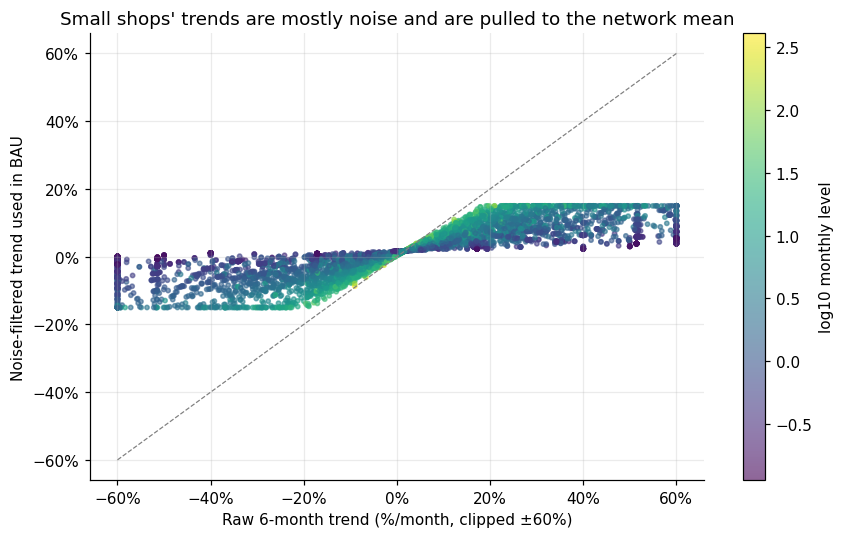

In [22]:
print(f"μ (trend chung) = {lt_main.attrs['mu']:+.2%}/tháng | τ (độ phân tán thật) = {np.sqrt(lt_main.attrs['tau2']):.3f} | "
      f"Q/df = {lt_main.attrs['Q_over_df']:.2f}")
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(elig["g_raw"].clip(-0.6, 0.6), elig["g_shrunk"], c=np.log10(elig["level"]), s=8,
                cmap="viridis", alpha=0.6)
ax.plot([-0.6, 0.6], [-0.6, 0.6], color="grey", ls="--", lw=0.8)
ax.set_xlabel("Raw 6-month trend (%/month, clipped ±60%)"); ax.set_ylabel("Noise-filtered trend used in BAU")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.colorbar(sc, label="log10 monthly level")
ax.set_title("Small shops' trends are mostly noise and are pulled to the network mean")
plt.tight_layout(); plt.show()

**Phân tích kết quả GĐ5.5**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Q/df = **1,70** > 1, tức có khác biệt thật giữa các shop ngoài nhiễu. Độ phân tán thật τ = **13%/tháng**; trend chung μ = +1,7%/tháng (trên chuỗi đã bỏ vòng đời).
- **[Tin cậy Cao · Giá trị Cao]** Mức tin B trung vị: **0,09** (shop ≤1/tháng) → 0,29 → 0,47 → 0,69 → **0,74** (shop >30/tháng). Trên biểu đồ, điểm màu tím (shop nhỏ) bị ép về gần 0, điểm màu vàng (shop lớn) bám đường chéo.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Không thể gán cùng một trend cho mọi shop (vì τ > 0), nhưng cũng không thể tin trend thô của shop nhỏ. Lọc nhiễu giải quyết cả hai. *Lời thường:* "shop càng lớn, nhóm càng tin xu hướng riêng của shop; shop nhỏ thì phần lớn biến động là ngẫu nhiên".

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ GĐ6:** g̃ là tín hiệu tốt nhất về **hướng**, nhưng chưa trả lời được **bao nhiêu phần** còn kéo dài sang tương lai.

---
## GĐ6 · Trend kéo dài bao nhiêu? Kiểm định độ bền và hiệu chỉnh κ

**Mục đích giai đoạn:** biến yêu cầu *"kéo dài trend thêm 6 tháng"* thành một con số có bằng chứng: κ = tỷ lệ trend quá khứ còn tiếp diễn (κ = 1: kéo dài toàn bộ; κ = 0: không kéo dài).

**Phương pháp tổng thể:** tại nhiều thời điểm gốc trong quá khứ, chỉ dùng dữ liệu đến thời điểm đó để tính trend, rồi đo tăng trưởng **thực tế** 6 tháng sau → hồi quy ra κ → kiểm tra trực quan → kiểm tra nhãn trend có dự báo được hay không.

### GĐ6.1–6.2 · Hiệu chỉnh κ trên 10 thời điểm gốc (không rò rỉ)
**Mục đích:** ước lượng κ ổn định, không dùng dữ liệu tương lai.

**Cách làm:**
1. Với mỗi gốc T từ 06/2025 đến 03/2026: chạy lại mùa vụ, vòng đời, `level_trend` **chỉ với dữ liệu ≤ T**.
2. Đo tăng trưởng thực tế: ln[(TB y* của 6 tháng sau + 0,5)/(L + 0,5)].
3. Hồi quy có trọng số theo L: tăng trưởng = a + κ·[g̃·(3,5 − t̄)]. So sánh với chính phép hồi quy đó dùng trend **thô**.
4. κ̂ = trung vị qua các gốc (bền với gốc ngoại lai).

In [23]:
def calibrate_kappa(df, origins, metric="signed_contracts", horizon=CFG["HORIZON"], c=CFG["SMOOTH_C"],
                    min_shops=CFG["KAPPA_MIN_SHOPS"], last_actual=CFG["LAST_ACTUAL"]):
    """κ = phần trend sau lọc nhiễu còn kéo dài sang `horizon` tháng sau, ước lượng tại nhiều gốc (dữ liệu ≤ gốc)."""
    rows, pooled = [], []
    for T in origins:
        if T + pd.DateOffset(months=horizon) > last_actual:
            continue
        se = estimate_season(df, T, metric)
        life = estimate_lifecycle(df, T)
        lt = level_trend(df, T, se, metric, life=life)
        lt = lt.loc[lt["n_valid"].ge(CFG["MIN_VALID_FOR_TREND"]) & lt["level"].gt(0)]
        fut = df.loc[df["month"].between(T + pd.DateOffset(months=1), T + pd.DateOffset(months=horizon))]
        fut = fut.assign(ys=fut[metric] / (season_factor(fut["month"], se) * life["f"](fut["age"])))
        d = lt.join(fut.groupby("shop_id")["ys"].mean().rename("fbar"), how="inner")
        if len(d) < min_shops:
            continue
        d["growth"] = np.log((d["fbar"] + c) / (d["level"] + c))
        d["x"] = d["g_shrunk"] * ((horizon + 1) / 2 - d["t_bar"])
        d["x_raw"] = d["g_raw"].clip(-1, 1) * ((horizon + 1) / 2 - d["t_bar"])
        W = np.sqrt(d["level"].to_numpy())
        fit = lambda x: np.linalg.lstsq(np.column_stack([np.ones(len(d)), x]) * W[:, None],
                                        d["growth"].to_numpy() * W, rcond=None)[0][1]
        rows.append({"origin": T.strftime("%Y-%m"), "shops": len(d),
                     "kappa (trend sau lọc)": fit(d["x"].to_numpy()), "kappa (trend thô)": fit(d["x_raw"].to_numpy())})
        pooled.append(d.assign(origin=T))
    tab = pd.DataFrame(rows)
    kappa = float(np.clip(tab["kappa (trend sau lọc)"].median(), 0, 1)) if len(tab) else 0.0
    return kappa, tab, (pd.concat(pooled) if pooled else pd.DataFrame())


KAPPA, kappa_tab, kappa_pool = calibrate_kappa(phys, CFG["KAPPA_ORIGINS"])
display(kappa_tab)
print(f"κ̂ (trung vị các gốc) = {KAPPA:.3f}")

,origin,shops,kappa (trend sau lọc),kappa (trend thô)
0,2025-06,216,0.3470,0.0964
1,2025-07,462,0.2736,0.0919
2,2025-08,765,0.2791,0.0878
3,2025-09,1105,0.3335,0.0897
4,2025-10,1572,0.4473,0.1292
5,2025-11,2046,0.5083,0.1485
6,2025-12,2472,0.3772,0.1347
7,2026-01,2778,0.3626,0.1347
8,2026-02,3214,0.2019,0.0702
9,2026-03,3587,0.3701,0.1146


κ̂ (trung vị các gốc) = 0.355


### GĐ6.3–6.4 · Kiểm tra trực quan và kiểm tra nhãn trend
**Mục đích:** (6.3) giám khảo nhìn một biểu đồ là hiểu κ; (6.4) kiểm tra nhãn "Đi xuống" có đáng tin để cảnh báo sớm không.

**Cách làm:**
- (6.3) Gộp các gốc, chia shop thành 10 nhóm theo mức tăng hàm ý nếu kéo dài trend 100%; vẽ tăng trưởng thực tế so với đường κ = 1 và đường κ̂.
- (6.4) Gắn nhãn tại 03/2026 (chỉ dữ liệu ≤ 03/2026); đo doanh số 04–09/2026 so với mức nền của từng nhóm nhãn.

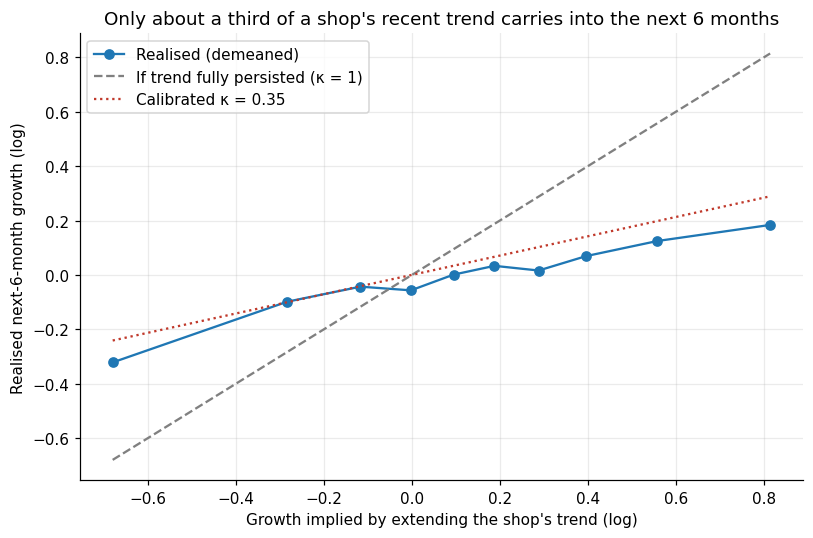

,shops,level_03/2026,avg_04–09/2026,realised_change
trend_label,,,,
Chưa đủ dữ liệu,"1,312.0000","4,949.3648","5,923.9216",0.1969
Đi lên,183.0000,"1,136.3356","1,476.6349",0.2995
Đi xuống,129.0000,696.0832,484.7033,-0.3037
Đứng yên,"3,275.0000","13,701.6401","13,675.8243",-0.0019


In [24]:
kp = kappa_pool.copy()
kp["decile"] = pd.qcut(kp["x"], 10, labels=False, duplicates="drop")
gmean = np.average(kp["growth"], weights=kp["level"])
dec = kp.groupby("decile").apply(lambda d: pd.Series({
    "predicted_if_full_trend": np.average(d["x"], weights=d["level"]),
    "realised": np.average(d["growth"], weights=d["level"]) - gmean}))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(dec["predicted_if_full_trend"], dec["realised"], marker="o", label="Realised (demeaned)")
lim = [dec["predicted_if_full_trend"].min(), dec["predicted_if_full_trend"].max()]
ax.plot(lim, lim, ls="--", color="grey", label="If trend fully persisted (κ = 1)")
ax.plot(lim, [KAPPA * v for v in lim], ls=":", color="#c0392b", label=f"Calibrated κ = {KAPPA:.2f}")
ax.set_xlabel("Growth implied by extending the shop's trend (log)"); ax.set_ylabel("Realised next-6-month growth (log)")
ax.set_title("Only about a third of a shop's recent trend carries into the next 6 months")
ax.legend(); plt.tight_layout(); plt.show()

season_mar = estimate_season(phys, CFG["HOLDOUT_ORIGIN"])
life_mar = estimate_lifecycle(phys, CFG["HOLDOUT_ORIGIN"])
lt_mar = level_trend(phys, CFG["HOLDOUT_ORIGIN"], season_mar, life=life_mar)
fut_mar = phys.loc[phys["month"].between("2026-04-01", "2026-09-01")]
fut_mar = fut_mar.assign(ys=fut_mar["signed_contracts"] / (season_factor(fut_mar["month"], season_mar)
                                                           * life_mar["f"](fut_mar["age"])))
lab_check = (lt_mar.join(fut_mar.groupby("shop_id")["ys"].mean().rename("fbar"), how="inner")
                   .groupby("trend_label")
                   .apply(lambda d: pd.Series({"shops": len(d), "level_03/2026": d["level"].sum(),
                                               "avg_04–09/2026": d["fbar"].sum(),
                                               "realised_change": d["fbar"].sum() / d["level"].sum() - 1})))
display(lab_check.drop(index="Ngủ đông (0 contract)", errors="ignore"))

**Phân tích kết quả GĐ6**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Qua 10 thời điểm gốc (216 → 3.587 shop mỗi gốc), κ của trend sau lọc nhiễu nằm trong **0,20–0,51**, **trung vị 0,355**, luôn dương và luôn xa 1. Với trend **thô**, κ chỉ **0,07–0,15**.
- **[Tin cậy Cao · Giá trị Cao]** Trên biểu đồ 10 nhóm, đường thực tế bám đường κ = 0,35 và cách xa đường κ = 1 ở cả hai đầu (shop tăng mạnh và shop giảm mạnh).
- **[Tin cậy Cao · Giá trị TB]** Kiểm tra nhãn tại 03/2026: shop Đi lên bán tiếp **+30,0%** so với mức nền, Đi xuống **−30,4%**, Đứng yên **−0,2%**.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** **Chỉ khoảng 1/3 đà tăng/giảm gần đây còn tiếp diễn**. Phần còn lại là biến động tạm thời và tự hồi về. "Kéo dài trend" theo nghĩa đen (κ = 1) sẽ thổi phồng cả chiều tăng lẫn chiều giảm; GĐ9 xác nhận κ = 1 làm BAU lệch +18,6%.
- **[Tin cậy Cao · Giá trị Cao]** Lọc nhiễu **làm tăng gấp khoảng 3 lần** giá trị dự báo của trend (κ thô trung vị khoảng 0,10 so với κ sau lọc 0,35). Đây là bằng chứng phương pháp ở GĐ5 làm đúng việc.
- **[Tin cậy Cao · Giá trị TB]** Nhãn trend **giữ được chiều**: shop "Đi xuống" thật sự bán kém hơn mức nền của nó trong 6 tháng sau. Nhãn đủ tin cậy làm **cảnh báo sớm**, nhưng không dùng nhãn để ngoại suy độ lớn.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ GĐ7:** BAU dùng κ = 0,355. *Nói bằng lời thường:* "Lịch sử cho thấy khoảng 1/3 đà tăng/giảm gần đây của một shop còn tiếp diễn trong 6 tháng tới. BAU chỉ kéo dài đúng phần đó."
- **→ Bước 7 (sensitivity):** thử κ = 0 và κ = 1 bằng tham số của `forecast_path`. κ theo từng gốc đã được lưu trong `bau_params.json`.
- **Giả thuyết → Bước 5:** shop có trend tăng **bền** (đi lên ở nhiều gốc liên tiếp) có thể đang có lợi thế thật (vị trí, chủ shop, SA giỏi). Đây là nhóm đáng học hỏi khi chọn benchmark.

---
## GĐ7 · Lắp ráp BAU (contract) cho 10/2026 → 03/2027

**Mục đích giai đoạn:** mọi shop Active có BAU hợp lệ (không âm, không NaN, không tùy tiện) cho từng tháng và trung bình 6 tháng.

**Phương pháp tổng thể:** áp công thức cho shop đủ dữ liệu (7.1) → quy tắc biên có bằng chứng cho shop thiếu dữ liệu (7.2) → tổng hợp, đối chiếu với CA (7.3).

### GĐ7.1 · Công thức BAU
**Mục đích:** ghép 4 thành phần đã kiểm chứng thành dự báo cho từng shop × tháng.

**Cách làm:** BAU(i, h) = L(i) × e^(κ·g̃(i)·(h − t̄(i))) × f(tuổi(i) + h) × S(tháng h), với h = 1…6. Dạng nhân nên BAU luôn ≥ 0. Tính hoàn toàn bằng ma trận numpy, không vòng lặp theo shop.

In [25]:
def forecast_path(lt, season, kappa, origin, horizon=CFG["HORIZON"], life=None):
    """Ma trận dự báo shop × h. life → nhân hệ số vòng đời theo tuổi tương lai."""
    fmonths = pd.date_range(origin + pd.DateOffset(months=1), periods=horizon, freq="MS")
    h = np.arange(1, horizon + 1)
    growth = np.exp(kappa * lt["g_shrunk"].to_numpy()[:, None] * (h[None, :] - lt["t_bar"].to_numpy()[:, None]))
    lf = life["f"](lt["age_origin"].to_numpy()[:, None] + h[None, :]) if life else 1.0
    F = lt["level"].to_numpy()[:, None] * growth * lf * season_factor(fmonths, season)[None, :]
    return pd.DataFrame(F, index=lt.index, columns=fmonths)


F_main = forecast_path(lt_main, season_main, KAPPA, CFG["LAST_ACTUAL"], life=LIFE_MAIN)
print(f"Dự báo theo công thức cho {len(F_main):,} shop × {F_main.shape[1]} tháng")

Dự báo theo công thức cho 9,084 shop × 6 tháng


### GĐ7.2 · Quy tắc biên cho shop thiếu dữ liệu
**Mục đích:** không shop nào có BAU tùy tiện; đặc biệt **không** mặc định BAU = 0 khi chưa có bằng chứng.

**Cách làm:**

| Trường hợp | Cách tính BAU | Căn cứ |
|---|---|---|
| Mới mở trong 09/2026 (chỉ có tháng khai trương) | Trung vị mức nền của shop mới **cùng cỡ × ngành** × f(tuổi 1…6) × S | Không có tháng đầy đủ nào để đo |
| Mức nền = 0 (mọi tháng đầy đủ trong cửa sổ đều 0) | **Tỷ lệ nền thực nghiệm**: trong lịch sử, shop có đúng n tháng đầy đủ toàn 0 thì 6 tháng sau bán TB bao nhiêu | Đo trên 10 thời điểm gốc |
| Chưa từng phát sinh contract | 0 | Không có tín hiệu nào |
| VIRTUAL | Cùng công thức, tính riêng, **báo cáo riêng** | QƯ7 |

In [26]:
# VIRTUAL
lt_virtual = level_trend(panel.loc[~panel["is_physical"]], CFG["LAST_ACTUAL"], season_main)
F_virtual = forecast_path(lt_virtual, season_main, KAPPA, CFG["LAST_ACTUAL"])
lt_all = pd.concat([lt_main, lt_virtual])
# Mới mở 09/2026
new_lv = (lt_main.join(shops[["shop_category", "SALESROOM_PRODUCT", "shop_age_group"]])
                 .query("shop_age_group == 'shop mới' and level > 0")
                 .groupby(["shop_category", "SALESROOM_PRODUCT"])["level"].median())
launch_only = shops.index[shops["data_status"].str.startswith("Mới mở")]
lv_launch = pd.Series([new_lv.get((shops.at[s, "shop_category"], shops.at[s, "SALESROOM_PRODUCT"]), new_lv.median())
                       for s in launch_only], index=launch_only, dtype=float)
F_launch = pd.DataFrame(lv_launch.to_numpy()[:, None] * LIFE_MAIN["f"](np.arange(1, CFG["HORIZON"] + 1))[None, :]
                        * season_factor(FC_MONTHS, season_main)[None, :], index=launch_only, columns=FC_MONTHS)


# Mức nền = 0 → tỷ lệ nền thực nghiệm
def zero_base_rates(df, origins, horizon=CFG["HORIZON"], window=CFG["WINDOW"]):
    """Shop có n tháng đầy đủ toàn 0 trong cửa sổ tại gốc T → TB contract/tháng của 6 tháng sau (gộp các gốc)."""
    rows = []
    for T in origins:
        if T + pd.DateOffset(months=horizon) > CFG["LAST_ACTUAL"]:
            continue
        w = df.loc[df["month"].between(T - pd.DateOffset(months=window - 1), T) & df["valid"]]
        g = w.groupby("shop_id")["signed_contracts"].agg(["size", "sum"])
        z = g.loc[g["sum"].eq(0), "size"].rename("n_zero")
        fut = df.loc[df["month"].between(T + pd.DateOffset(months=1), T + pd.DateOffset(months=horizon))]
        rows.append(z.to_frame().join(fut.groupby("shop_id")["signed_contracts"].mean().rename("future_mean")))
    r = pd.concat(rows)
    return r.groupby("n_zero")["future_mean"].agg(["mean", "size"]).rename(columns={"mean": "rate", "size": "obs"})


zero_rates = zero_base_rates(phys, CFG["KAPPA_ORIGINS"])
display(zero_rates.rename_axis("số tháng đầy đủ toàn 0").T)
zero_shops = lt_main.index[lt_main["level"].le(0)]
zr = lt_main.loc[zero_shops, "n_valid"].map(zero_rates["rate"]).fillna(zero_rates["rate"].iloc[-1])
F_zero = pd.DataFrame(zr.to_numpy()[:, None] * season_factor(FC_MONTHS, season_main)[None, :],
                      index=zero_shops, columns=FC_MONTHS)
F_main = F_main.drop(index=zero_shops)
# Chưa từng bán
never = shops.index[shops["data_status"].eq("Chưa phát sinh doanh số")]
F_never = pd.DataFrame(0.0, index=never, columns=FC_MONTHS)
F_all = pd.concat([F_main, F_zero, F_virtual, F_launch, F_never])
F_all = F_all.loc[~F_all.index.duplicated()]
display(pd.Series({"Mới mở 09/2026 – mức nền mượn (TB)": lv_launch.mean(),
                   "VIRTUAL – mức nền": float(lt_virtual["level"].iloc[0])}).rename("contract/tháng").to_frame())

số tháng đầy đủ toàn 0,1,2,3,4,5,6
rate,0.8670,0.6319,0.5022,0.3987,0.3681,0.3089
obs,"1,635.0000","1,093.0000",763.0000,551.0000,427.0000,"1,407.0000"


,contract/tháng
Mới mở 09/2026 – mức nền mượn (TB),1.8466
VIRTUAL – mức nền,9.5603


**Phân tích kết quả GĐ7.2**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Tỷ lệ nền thực nghiệm **giảm đều** theo số tháng toàn 0: 1 tháng → **0,87** contract/tháng; 2 → 0,63; 3 → 0,50; 4 → 0,40; 5 → 0,37; 6 → **0,31**. Mỗi tỷ lệ dựa trên 427–1.635 quan sát.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Shop bán 0 **không phải** shop "chết": lịch sử cho thấy một shop có 1 tháng đầy đủ bằng 0 vẫn bán khoảng 0,87 contract/tháng sau đó. Gán BAU = 0 sẽ là lỗi hệ thống. Ở Bước 5, nếu BAU = 0 thì toàn bộ Attainable sẽ bị tính là "cơ hội", phóng đại gap của 1.555 shop.
- **[Tin cậy Cao · Giá trị TB]** "Càng ngủ lâu, càng khó tỉnh": từ 1 lên 6 tháng toàn 0, tỷ lệ nền giảm khoảng 64%. Đây là một chỉ báo hành vi rõ ràng của đối tác.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 6:** 1.186 shop "Ngủ đông" (≥3 tháng toàn 0) có thể cần can thiệp kiểu **tái kích hoạt hoặc rà soát hợp tác**, khác với tăng năng suất.
- **Câu hỏi cho Sales:** các shop ngủ đông còn SA được phân công không? Nếu còn thì đây là chi phí nhân sự không tạo doanh số. Dữ liệu `emp_2_salesroom` có thể kiểm tra (đề xuất bổ sung, ngoài phạm vi BAU).

### GĐ7.3 · Tổng hợp BAU contract và đối chiếu với Current Actual
**Mục đích:** ra bảng BAU một dòng/shop; kiểm tra tổng thể hợp lý; nhìn phân phối ở cấp shop.

**Cách làm:** ghép trạng thái + trend + BAU 6 tháng + CA; BAU = TB 6 tháng. So tổng BAU với CA và vẽ đường thực tế nối với BAU.

**Hậu kiểm định:** `assert` không NaN, không âm, 1 dòng/shop.

,Current Actual (TB 07–09/2026),BAU (TB 10/2026–03/2027),BAU / CA − 1
Shop vật lý – contract/tháng,"37,664.0000","37,733.6125",0.0018


,shops,bau_total
bau_method,,
level×trend×season,7529,"35,972.8684"
peer_new_shop_median,495,"1,075.4093"
zero_level_base_rate,1555,685.3348
zero_never_sold,2173,0.0000


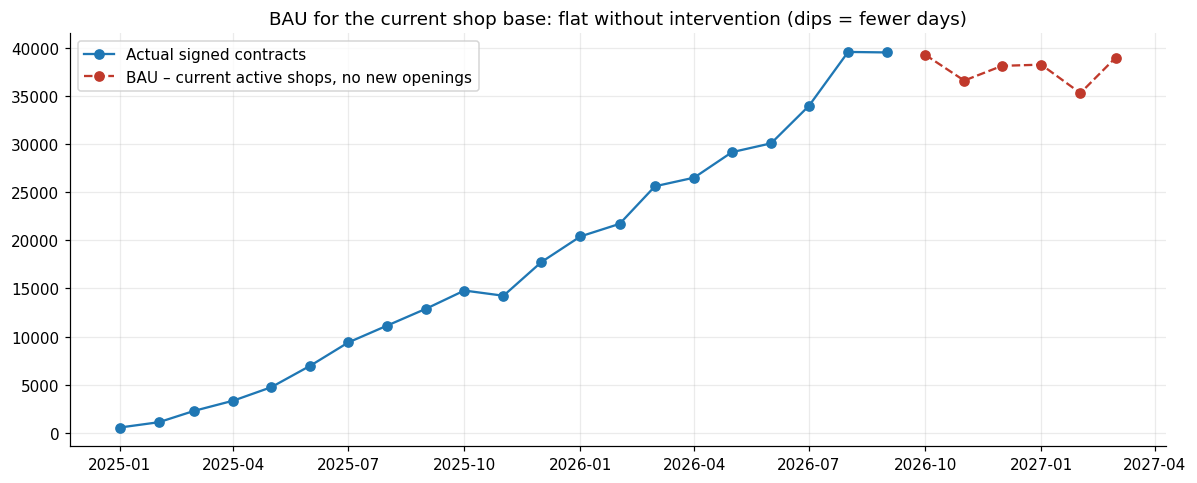

,BAU/CA − 1 (cấp shop)
count,"7,657.0000"
mean,0.2349
std,1.0620
min,-0.8462
10%,-0.3362
25%,-0.1983
50%,-0.0401
75%,0.1657
90%,0.8894
max,8.4374


In [27]:
bau = shops.join(lt_all[["n_valid", "level", "g_raw", "z", "g_shrunk", "B_shrink", "trend_label", "size_band"]])
bau["bau_method"] = np.select([bau.index.isin(launch_only), bau.index.isin(never), bau["level"].le(0)],
                              ["peer_new_shop_median", "zero_never_sold", "zero_level_base_rate"],
                              default="level×trend×season")
bau["trend_label"] = bau["trend_label"].fillna(pd.Series(
    np.where(bau.index.isin(never), "Chưa phát sinh doanh số", "Chưa đủ dữ liệu"), index=bau.index))
monthly_cols = [f"bau_contracts_{m:%Y_%m}" for m in FC_MONTHS]
bau[monthly_cols] = F_all.reindex(bau.index).to_numpy()
bau["bau_contracts"] = bau[monthly_cols].mean(axis=1)
ca = (panel.loc[panel["month"].ge(CFG["CA_START"])]
           .groupby("shop_id")[["signed_contracts", "funded_volume", "cross_sell_contracts",
                                "cross_sell_funded_volume", "cross_sell_booked_elsewhere_or_online"]].mean()
           .add_prefix("ca_"))
bau = bau.join(ca)
bau["bau_vs_ca"] = bau["bau_contracts"] / bau["ca_signed_contracts"].replace(0, np.nan) - 1

assert np.isfinite(bau[monthly_cols]).all().all(), "BAU có NaN/inf"
assert (bau[monthly_cols] >= 0).all().all(), "BAU âm"
assert bau.index.is_unique and len(bau) == kpi["shop_id"].nunique()
phys_idx = bau.index != "VIRTUAL"
summary = pd.DataFrame({"Current Actual (TB 07–09/2026)": [bau.loc[phys_idx, "ca_signed_contracts"].sum()],
                        "BAU (TB 10/2026–03/2027)": [bau.loc[phys_idx, "bau_contracts"].sum()]},
                       index=["Shop vật lý – contract/tháng"])
summary["BAU / CA − 1"] = summary.iloc[:, 1] / summary.iloc[:, 0] - 1
display(summary)
display(bau.loc[phys_idx].groupby("bau_method").agg(shops=("bau_contracts", "size"), bau_total=("bau_contracts", "sum")))
net_path = pd.concat([phys.groupby("month")["signed_contracts"].sum().rename("Actual"),
                      bau.loc[phys_idx, monthly_cols].sum().set_axis(FC_MONTHS).rename("BAU")], axis=1)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(net_path.index, net_path["Actual"], marker="o", label="Actual signed contracts")
ax.plot(net_path.index, net_path["BAU"], marker="o", ls="--", color="#c0392b",
        label="BAU – current active shops, no new openings")
ax.set_title("BAU for the current shop base: flat without intervention (dips = fewer days)")
ax.legend(); plt.tight_layout(); plt.show()
display(bau.loc[phys_idx, "bau_vs_ca"].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("BAU/CA − 1 (cấp shop)"))

**Phân tích kết quả GĐ7.3**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** BAU shop vật lý = **37.734 contract/tháng**, so với CA = 37.664 (**+0,2%**). Cấu phần:
  - 7.529 shop theo công thức: 35.973 contract/tháng.
  - 495 shop mới mở: 1.075 contract/tháng.
  - 1.555 shop mức nền 0: 685 contract/tháng.
  - 2.173 shop chưa từng bán: 0.
- **[Tin cậy Cao · Giá trị TB]** Theo tháng: 10/2026 là 39.258 · 11/2026 là 36.574 · 12/2026 là 38.104 · 01/2027 là 38.228 · **02/2027 là 35.276** · 03/2027 là 38.963. Chênh lệch giữa các tháng gần như hoàn toàn do số ngày.
- **[Tin cậy Cao · Giá trị Cao]** Ở cấp shop, BAU/CA − 1 có trung vị −4,0%, tứ phân vị **−19,8% → +16,6%**, P10 = −33,6%, P90 = +89%.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** **Nếu không làm gì khác, mạng lưới shop hiện tại đi ngang.** Đường đỏ dừng hẳn đà tăng của đường xanh, vì đà tăng đó đến từ mở shop (GĐ3.1). Mọi mục tiêu tăng trưởng phải đến từ **can thiệp** (Attainable, Bước 3) hoặc **mở thêm shop**.
- **[Tin cậy Cao · Giá trị Cao]** Tổng đi ngang **che giấu** biến động lớn ở cấp shop: khoảng 1/4 shop sẽ bán kém CA hiện tại khoảng 20% trở lên, 1/4 khác sẽ bán hơn khoảng 17%. Con số tổng không dùng để phân bổ nguồn lực được; đây là lý do BAU phải tính **riêng từng shop**.
- **[Tin cậy TB · Giá trị TB]** P90 = +89% đến từ shop rất nhỏ hoặc shop mới, nơi CA là 0–1 contract (mẫu số nhỏ). Không nên đọc tỷ lệ này ở shop nhỏ.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 5:** Opportunity gap = Attainable − `bau_contracts` (và `bau_funded_volume`). BAU là **mốc trừ**: BAU đã tính sẵn phần tự giảm của shop mới và phần hồi phục của shop vừa sụt, nên gap chỉ còn phần **do can thiệp**.
- **→ Bước 3:** ràng buộc Attainable ≥ BAU cho từng shop. Nếu benchmark cho kết quả thấp hơn BAU thì lấy BAU.
- **Giả thuyết → Bước 4:** nếu Market Ceiling của một tỉnh thấp hơn tổng BAU của các shop trong tỉnh, tỉnh đó có thể đã bão hòa.

---
## GĐ8 · BAU funded volume & cross-sell (không double count)

**Mục đích giai đoạn:** đo doanh số bằng cả **contract và funded volume**, theo lưu ý của Bước 1 (cross-sell tính riêng, không cộng thẳng).

**Phương pháp tổng thể:** ticket có độ tin cậy (8.1) → BAU funded (8.2) → BAU cross-sell (8.3) → tỷ trọng ký nơi khác (8.4) → tổng đóng góp không trùng (8.5).

### GĐ8.1–8.2 · Ticket có độ tin cậy và BAU funded volume
**Mục đích:** chuyển BAU contract sang tiền mà không để vài hợp đồng lớn làm ticket của shop nhỏ tăng vọt.

**Cách làm (credibility kiểu Bühlmann):**
1. Ticket riêng của shop = Σ funded / Σ contract (04–09/2026); ticket nhóm = cùng phép tính trên nhóm cỡ × ngành.
2. ticket = Z·ticket riêng + (1 − Z)·ticket nhóm, với Z = N/(N + k). Hệ số k = phương sai trong shop / phương sai giữa shop, **ước lượng từ dữ liệu**.
3. BAU funded = BAU contract × ticket.

In [28]:
win_mask = panel["month"].gt(CFG["LAST_ACTUAL"] - pd.DateOffset(months=CFG["WINDOW"])) & panel["valid"]
tk = panel.loc[win_mask].groupby("shop_id").agg(N=("signed_contracts", "sum"), V=("funded_volume", "sum"))
sm_tk = panel.loc[win_mask & panel["signed_contracts"].gt(0), ["shop_id", "signed_contracts", "funded_volume"]].copy()
sm_tk["a"] = sm_tk["funded_volume"] / sm_tk["signed_contracts"]
sm_tk = sm_tk.join(tk, on="shop_id")
sm_tk["abar"] = sm_tk["V"] / sm_tk["N"]
n_months = sm_tk.groupby("shop_id")["a"].transform("size")
# Phương sai trong shop (mức hợp đồng) ≈ Σ n_t(a_t − ā)² / Σ(T_i − 1); giữa shop = Var(ā) − E[σ²_w/N]
s2_within = float((sm_tk["signed_contracts"] * (sm_tk["a"] - sm_tk["abar"]) ** 2).sum()
                  / (n_months.groupby(sm_tk["shop_id"]).first() - 1).clip(lower=0).sum())
tk = tk.loc[tk["N"].gt(0)].assign(ticket_own=lambda d: d["V"] / d["N"])
var_between = max(float(np.average((tk["ticket_own"] - np.average(tk["ticket_own"], weights=tk["N"])) ** 2,
                                   weights=tk["N"])) - s2_within * float((1 / tk["N"]).mean()), 1e-9)
K_CRED = float(np.clip(s2_within / var_between, 1, 200))
tk = tk.join(shops[["shop_category", "SALESROOM_PRODUCT"]])
peer_tk = (tk.groupby(["shop_category", "SALESROOM_PRODUCT"])[["V", "N"]].sum()
             .pipe(lambda d: d["V"] / d["N"]).rename("ticket_peer"))
tk = tk.join(peer_tk, on=["shop_category", "SALESROOM_PRODUCT"])
tk["Z"] = tk["N"] / (tk["N"] + K_CRED)
tk["ticket_bau"] = tk["Z"] * tk["ticket_own"] + (1 - tk["Z"]) * tk["ticket_peer"]

bau = bau.join(tk[["ticket_own", "ticket_peer", "Z", "ticket_bau"]])
fallback_peer = bau[["shop_category", "SALESROOM_PRODUCT"]].apply(tuple, axis=1).map(peer_tk)
bau["ticket_bau"] = bau["ticket_bau"].fillna(fallback_peer).fillna(float(tk["V"].sum() / tk["N"].sum()))
bau["bau_funded_volume"] = bau["bau_contracts"] * bau["ticket_bau"]
print(f"Credibility k = {K_CRED:.1f} hợp đồng")
display((peer_tk / 1e6).unstack().round(1).rename_axis(columns="ticket nhóm (triệu đồng)"))

Credibility k = 4.2 hợp đồng


ticket nhóm (triệu đồng),CD,NS,TW,VIRTUAL
shop_category,,,,
Big,10.6000,15.6000,21.2000,NaN
Medium,11.8000,14.8000,22.1000,NaN
Small,10.5000,12.6000,21.2000,NaN
Virtual,NaN,NaN,NaN,20.8000


**Phân tích kết quả GĐ8.1–8.2**

**① Pattern**
- **[Tin cậy Cao · Giá trị TB]** k = **4,2 hợp đồng**: shop có khoảng 4 hợp đồng trong 6 tháng thì tin 50% ticket riêng; shop có 40 hợp đồng thì tin khoảng 90%.
- **[Tin cậy Cao · Giá trị Cao]** Ticket nhóm chênh nhau rất lớn theo ngành: **TW 21–22 triệu**, NS 12,6–15,6 triệu, **CD 10,5–11,8 triệu** mỗi hợp đồng. Trong cùng ngành, ticket gần như không đổi theo cỡ shop.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Một contract TW có giá trị funded **gấp khoảng 2 lần** một contract CD. Bước 5 cần nhìn gap theo **cả hai** đơn vị (contract và tiền); nếu chỉ nhìn số contract, shop TW sẽ bị xếp thấp oan.
- **[Tin cậy Cao · Giá trị TB]** Ticket phụ thuộc chủ yếu vào **ngành**, gần như không phụ thuộc **cỡ shop**. Vì vậy chọn nhóm cỡ × ngành để mượn ticket là hợp lý.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 5/6:** xếp ưu tiên theo funded gap có thể khác hẳn xếp theo contract gap. Nhóm nên chốt một đơn vị chính (gợi ý: funded volume, vì gắn trực tiếp với doanh thu lãi).

### GĐ8.3–8.4 · BAU cross-sell và tỷ trọng ký ở nơi khác
**Mục đích:** dự báo phần doanh số shop **tạo ra qua lead** (kể cả khi khách ký ở shop khác hoặc online), và tách riêng phần là đóng góp **thêm**.

**Cách làm:**
1. Cùng hàm `level_trend` + `forecast_path` trên `cross_sell_contracts`, cửa sổ 04–09/2026. **Không** dùng mùa vụ (B = 0) vì lead chỉ có từ 31/12/2025; **không** dùng vòng đời vì cross-sell phụ thuộc tệp khách cũ, không phụ thuộc tuổi shop.
2. Tỷ trọng ký nơi khác: theo số lượng lấy từ `cross_sell_booked_elsewhere_or_online`; theo tiền lấy từ `cross_sell_attribution.csv` (`contract_skp_salesroom ≠ lead_skp_salesroom`). Cả hai đều có credibility về mức chung của mạng lưới (K = 10 hợp đồng).

In [29]:
season_none = {**season_main, "s_used": season_main["s_used"] * 0, "B": 0.0}
lt_x = level_trend(phys, CFG["LAST_ACTUAL"], season_none, metric="cross_sell_contracts",
                   min_month=CFG["XSELL_FIRST_FULL_MONTH"])
F_x = forecast_path(lt_x, season_none, KAPPA, CFG["LAST_ACTUAL"])
bau["bau_xsell_contracts"] = F_x.mean(axis=1).reindex(bau.index).fillna(0.0)
xs = (panel.loc[win_mask & panel["month"].ge(CFG["XSELL_FIRST_FULL_MONTH"])].groupby("shop_id")
           [["cross_sell_contracts", "cross_sell_funded_volume", "cross_sell_booked_elsewhere_or_online"]].sum())
net_else_share = xs["cross_sell_booked_elsewhere_or_online"].sum() / xs["cross_sell_contracts"].sum()
net_xs_ticket = xs["cross_sell_funded_volume"].sum() / xs["cross_sell_contracts"].sum()
K_X = 10.0
xs["else_share"] = (xs["cross_sell_booked_elsewhere_or_online"] + K_X * net_else_share) / (xs["cross_sell_contracts"] + K_X)
xs["xs_ticket"] = (xs["cross_sell_funded_volume"] + K_X * net_xs_ticket) / (xs["cross_sell_contracts"] + K_X)
bau = bau.join(xs[["else_share", "xs_ticket"]])
bau["else_share"] = bau["else_share"].fillna(net_else_share)
bau["xs_ticket"] = bau["xs_ticket"].fillna(net_xs_ticket)
bau["bau_xsell_funded_volume"] = bau["bau_xsell_contracts"] * bau["xs_ticket"]
bau["bau_xsell_elsewhere_contracts"] = bau["bau_xsell_contracts"] * bau["else_share"]
net_f_share = net_else_share
if PATH_XSELL:
    xa = pd.read_csv(PATH_XSELL, usecols=["credited_shop_id", "contract_skp_salesroom", "lead_skp_salesroom",
                                          "sign_month", "funded_amount"],
                     dtype={"credited_shop_id": str}, parse_dates=["sign_month"])
    xa = xa.loc[xa["sign_month"].between(max(CFG["XSELL_FIRST_FULL_MONTH"],
                                             CFG["LAST_ACTUAL"] - pd.DateOffset(months=CFG["WINDOW"] - 1)),
                                         CFG["LAST_ACTUAL"])]
    xa["f_else"] = xa["funded_amount"].fillna(0) * xa["contract_skp_salesroom"].ne(xa["lead_skp_salesroom"])
    fx = xa.groupby("credited_shop_id").agg(n=("funded_amount", "size"), f_all=("funded_amount", "sum"),
                                            f_else=("f_else", "sum"))
    net_f_share = fx["f_else"].sum() / fx["f_all"].sum()
    z = fx["n"] / (fx["n"] + K_X)
    fx["else_share_funded"] = (z * (fx["f_else"] / fx["f_all"].replace(0, np.nan)).fillna(net_f_share)
                               + (1 - z) * net_f_share)
    bau["else_share_funded"] = fx["else_share_funded"].reindex(bau.index).fillna(net_f_share)
    print(f"Khớp attribution: {len(xa):,} hợp đồng cross-sell (04–09/2026)")
else:
    bau["else_share_funded"] = bau["else_share"]
bau["bau_xsell_elsewhere_funded"] = bau["bau_xsell_funded_volume"] * bau["else_share_funded"]
print(f"Tỷ trọng cross-sell ký ở shop khác/online: theo số lượng {net_else_share:.1%} | theo tiền {net_f_share:.1%}")

Khớp attribution: 43,525 hợp đồng cross-sell (04–09/2026)
Tỷ trọng cross-sell ký ở shop khác/online: theo số lượng 18.3% | theo tiền 19.3%


### GĐ8.5 · Tổng đóng góp của shop (không double count) và đối chiếu
**Mục đích:** một con số "đóng góp tổng" cho mỗi shop mà không đếm trùng.

**Cách làm:** đóng góp tổng = BAU bán tại shop + BAU cross-sell **ký ở nơi khác**. Phần cross-sell ký tại chính shop đã nằm trong `signed_contracts`.

**Hậu kiểm định:** đối chiếu 4 chỉ tiêu BAU với CA; không có giá trị âm.

In [30]:
bau["bau_total_contribution_contracts"] = bau["bau_contracts"] + bau["bau_xsell_elsewhere_contracts"]
bau["bau_total_contribution_funded"] = bau["bau_funded_volume"] + bau["bau_xsell_elsewhere_funded"]
p_ = bau.loc[phys_idx]
recon = pd.DataFrame({
    "Current Actual (TB/tháng 07–09/2026)": [p_["ca_signed_contracts"].sum(), p_["ca_funded_volume"].sum() / 1e9,
                                             p_["ca_cross_sell_contracts"].sum(), p_["ca_cross_sell_funded_volume"].sum() / 1e9],
    "BAU (TB/tháng 10/2026–03/2027)": [p_["bau_contracts"].sum(), p_["bau_funded_volume"].sum() / 1e9,
                                       p_["bau_xsell_contracts"].sum(), p_["bau_xsell_funded_volume"].sum() / 1e9],
}, index=["Contract bán tại shop", "Funded tại shop (tỷ đồng)", "Contract cross-sell (ghi công)", "Funded cross-sell (tỷ đồng)"])
recon["BAU/CA − 1"] = recon.iloc[:, 1] / recon.iloc[:, 0] - 1
display(recon)
display(pd.Series({
    "Đóng góp tổng – contract/tháng": p_["bau_total_contribution_contracts"].sum(),
    "  trong đó cross-sell ký nơi khác": p_["bau_xsell_elsewhere_contracts"].sum(),
    "Đóng góp tổng – funded (tỷ đồng/tháng)": p_["bau_total_contribution_funded"].sum() / 1e9,
    "  trong đó cross-sell ký nơi khác (tỷ)": p_["bau_xsell_elsewhere_funded"].sum() / 1e9,
}).rename("BAU").to_frame())
assert (bau[["bau_funded_volume", "bau_xsell_contracts", "bau_total_contribution_funded"]] >= 0).all().all()

,Current Actual (TB/tháng 07–09/2026),BAU (TB/tháng 10/2026–03/2027),BAU/CA − 1
Contract bán tại shop,"37,664.0000","37,733.6125",0.0018
Funded tại shop (tỷ đồng),516.9066,520.4103,0.0068
Contract cross-sell (ghi công),"8,573.3333","8,992.3346",0.0489
Funded cross-sell (tỷ đồng),108.8896,114.4869,0.0514


,BAU
Đóng góp tổng – contract/tháng,"39,271.6344"
trong đó cross-sell ký nơi khác,"1,538.0219"
Đóng góp tổng – funded (tỷ đồng/tháng),539.0331
trong đó cross-sell ký nơi khác (tỷ),18.6228


**Phân tích kết quả GĐ8.3–8.5**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** BAU funded tại shop = **520,4 tỷ/tháng** (CA 516,9 tỷ, +0,7%).
- **[Tin cậy TB · Giá trị TB]** BAU cross-sell = **8.992 contract/tháng** (CA 8.573, **+4,9%**) và 114,5 tỷ/tháng. Cross-sell vẫn còn đà tăng.
- **[Tin cậy Cao · Giá trị Cao]** Cross-sell ký ở shop khác/online chiếm **18,3% số hợp đồng** nhưng **19,3% số tiền**.
- **[Tin cậy Cao · Giá trị Cao]** Đóng góp tổng = 37.734 + 1.538 = **39.272 contract/tháng**; 520,4 + 18,6 = **539,0 tỷ/tháng**.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Nếu chỉ nhìn doanh số ghi tại shop, mỗi shop bị **đánh giá thiếu khoảng 4%** đóng góp thật (1.538 / 37.734). Phần này lại có ticket cao hơn: hợp đồng chuyển sang online thường là vay tiền mặt hoặc thẻ (CL/CC). Đây chính là cơ chế "cross-sell from physical shops to online" mà đề mô tả.
- **[Tin cậy TB · Giá trị TB]** Cross-sell tăng nhanh hơn bán tại shop vì chương trình lead mới chạy từ đầu 2026, nhưng chỉ có 6 tháng lịch sử và không ước lượng được mùa vụ. **BAU cross-sell có độ tin cậy thấp hơn BAU bán tại shop**, cần ghi rõ khi trình bày kết quả.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **→ Bước 5:** nhóm cần chốt gap tính trên `bau_contracts` (chỉ tại shop) hay `bau_total_contribution_*` (kể cả cross-sell ký nơi khác). Gợi ý: dùng đóng góp tổng cho shop có nhiều lead, để không đánh giá thấp vai trò tạo cơ hội của shop vật lý.
- **→ Bước 5 (Demand):** Round 2 dùng khách cũ và lead làm nguồn demand. BAU cross-sell là phần demand **đã được hiện thực hóa**; phần lead NOT_INTEREST (75,9% theo Bước 1) là demand chưa khai thác.
- **Đề xuất bổ sung:** khi có thêm 6 tháng dữ liệu lead, ước lượng lại κ và mùa vụ riêng cho cross-sell.

---
## GĐ9 · Kiểm tra nội bộ để chọn thành phần mô hình (không thay thế Bước 7)

**Mục đích giai đoạn:** chứng minh hai lựa chọn thiết kế quan trọng nhất là đúng: (a) phải có đường vòng đời, (b) không kéo dài trend 100%. Backtest chính thức so với benchmark *"TB 3 tháng trước"*, nhiều thời điểm gốc, sensitivity và nhãn tin cậy thuộc **Bước 7**.

**Phương pháp tổng thể:** đứng ở 03/2026, mọi tham số chỉ dùng dữ liệu ≤ 03/2026 (κ chỉ từ các gốc ≤ 09/2025), dự báo 04–09/2026, so với thực tế. So 4 cách xây BAU, mỗi cách bỏ đúng một thành phần.
- **WAPE** = Σ|dự báo − thực tế| / Σ thực tế, trên tổng 6 tháng của từng shop (sai số cấp shop).
- **Bias** = (Σ dự báo − Σ thực tế) / Σ thực tế (độ lệch của tổng mạng lưới).

### GĐ9.1–9.2 · So 4 cách xây BAU
**Mục đích:** đo đóng góp của từng thành phần.

**Cách làm:** hàm `run_backtest()` dựng BAU tại bất kỳ gốc nào bằng đúng phương pháp của Bước 2 (đây cũng là hàm bàn giao cho Bước 7). Bốn phương án:
- ① Kéo dài trend thô 100% (kéo dài đúng nghĩa đen)
- ② BAU nhưng κ = 1
- ③ BAU không có đường vòng đời
- ④ BAU được chọn

In [31]:
def run_backtest(df, origin, metric="signed_contracts", kappa=None, shrink=None, window=CFG["WINDOW"],
                 day_adjust=True, use_life=True, horizon=CFG["HORIZON"]):
    """Đứng ở `origin`, dựng BAU bằng đúng phương pháp Bước 2 (mọi tham số chỉ dùng dữ liệu ≤ origin).
    Trả về bảng shop × {actual, BAU, FULL_TREND, NAIVE3, RAW_TREND} cho tổng `horizon` tháng sau.
    → Bước 7 dùng lại hàm này cho backtest chính thức."""
    if kappa is None:
        kappa, _, _ = calibrate_kappa(df, [o for o in CFG["KAPPA_ORIGINS"]
                                           if o + pd.DateOffset(months=horizon) <= origin], metric,
                                      last_actual=origin)
    se = estimate_season(df, origin, metric, shrink=shrink)
    if not day_adjust:
        se = {**se, "s_used": se["s_used"] * 0, "no_days": True}
    life = estimate_lifecycle(df, origin) if use_life else None
    lt = level_trend(df, origin, se, metric, window=window, life=life)
    fm = pd.date_range(origin + pd.DateOffset(months=1), periods=horizon, freq="MS")
    out = pd.DataFrame(index=lt.index)
    out["actual"] = df.loc[df["month"].isin(fm)].groupby("shop_id")[metric].sum().reindex(lt.index).fillna(0)
    out["BAU"] = forecast_path(lt, se, kappa, origin, horizon, life).sum(axis=1)
    out["FULL_TREND"] = forecast_path(lt, se, 1.0, origin, horizon, life).sum(axis=1)
    hist = df.loc[df["month"].between(origin - pd.DateOffset(months=window - 1), origin) & df["in_scope"]]
    out["NAIVE3"] = (hist.loc[hist["month"].gt(origin - pd.DateOffset(months=CFG["NAIVE_WINDOW"]))]
                         .groupby("shop_id")[metric].mean().reindex(lt.index).fillna(0) * horizon)
    hh = hist.assign(t=month_diff(hist["month"], pd.Series(origin, index=hist.index)).astype(float))
    g = hh.groupby("shop_id")
    tb, yb = g["t"].transform("mean"), g[metric].transform("mean")
    b = (((hh["t"] - tb) * (hh[metric] - yb)).groupby(hh["shop_id"]).sum()
         / ((hh["t"] - tb) ** 2).groupby(hh["shop_id"]).sum().replace(0, np.nan)).fillna(0)
    a0 = yb.groupby(hh["shop_id"]).first() - b * tb.groupby(hh["shop_id"]).first()
    H = np.arange(1, horizon + 1)
    raw = np.clip(a0.to_numpy()[:, None] + b.to_numpy()[:, None] * H[None, :], 0, None).sum(axis=1)
    out["RAW_TREND"] = pd.Series(raw, index=a0.index).reindex(lt.index).fillna(0)
    out["age_origin"] = lt["age_origin"]
    out.attrs.update({"kappa": kappa, "B": se["B"], "origin": origin})
    return out


def score(bt, col):
    A = bt["actual"]
    return {"WAPE": float((bt[col] - A).abs().sum() / A.sum()), "Bias": float((bt[col].sum() - A.sum()) / A.sum())}


bt_hold = run_backtest(phys, CFG["HOLDOUT_ORIGIN"])
bt_nolife = run_backtest(phys, CFG["HOLDOUT_ORIGIN"], use_life=False)
check = pd.DataFrame({
    "① Kéo dài trend thô 100% (nghĩa đen)": score(bt_hold, "RAW_TREND"),
    "② BAU nhưng tin trend 100% (κ = 1)": score(bt_hold, "FULL_TREND"),
    "③ BAU không có đường vòng đời": score(bt_nolife, "BAU"),
    "④ BAU được chọn": score(bt_hold, "BAU"),
}).T
print(f"Gốc 03/2026 | {len(bt_hold):,} shop | κ (chỉ dữ liệu cũ) = {bt_hold.attrs['kappa']:.3f}")
display(check)

Gốc 03/2026 | 5,496 shop | κ (chỉ dữ liệu cũ) = 0.306


,WAPE,Bias
① Kéo dài trend thô 100% (nghĩa đen),0.9773,0.4914
② BAU nhưng tin trend 100% (κ = 1),0.5874,0.1864
③ BAU không có đường vòng đời,0.4750,0.0698
④ BAU được chọn,0.4601,-0.0058


### GĐ9.3 · Bias theo tuổi shop
**Mục đích:** kiểm tra đường vòng đời có sửa đúng chỗ (shop non tuổi) hay không.

**Cách làm:** tách Bias của ③ và ④ cho shop < 6 tháng tuổi và ≥ 6 tháng tuổi tại gốc.

In [32]:
young = bt_hold["age_origin"].lt(6)
young_nl = bt_nolife["age_origin"].lt(6)
display(pd.DataFrame({
    "Shop <6 tháng tuổi": {"③ không vòng đời": score(bt_nolife.loc[young_nl], "BAU")["Bias"],
                           "④ BAU chọn": score(bt_hold.loc[young], "BAU")["Bias"]},
    "Shop ≥6 tháng tuổi": {"③ không vòng đời": score(bt_nolife.loc[~young_nl], "BAU")["Bias"],
                           "④ BAU chọn": score(bt_hold.loc[~young], "BAU")["Bias"]},
}).rename_axis("Bias"))

,Shop <6 tháng tuổi,Shop ≥6 tháng tuổi
Bias,,
③ không vòng đời,0.0929,0.0516
④ BAU chọn,-0.0926,0.0629


**Phân tích kết quả GĐ9**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** ① Kéo dài trend thô: WAPE **0,977**, Bias **+49,1%** · ② κ = 1: WAPE 0,587, Bias +18,6% · ③ Không vòng đời: WAPE 0,475, Bias +7,0% · ④ **BAU chọn: WAPE 0,460, Bias −0,6%**.
- **[Tin cậy Cao · Giá trị TB]** Theo tuổi: shop < 6 tháng có Bias **+9,3% → −9,3%** khi thêm vòng đời; shop ≥ 6 tháng có Bias +5,2% → +6,3%.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Làm đúng nghĩa đen "kéo dài trend 6 tháng" là **phương án tệ nhất**: sai số gần bằng chính doanh số và thổi phồng BAU toàn mạng lưới gần một nửa. Đây là bằng chứng mạnh nhất để bảo vệ cách làm trước giám khảo.
- **[Tin cậy Cao · Giá trị Cao]** **Đường vòng đời là thành phần quan trọng nhất:** bỏ nó thì Bias từ −0,6% lên +7,0%. κ < 1 là thành phần quan trọng thứ hai.
- **[Tin cậy TB · Giá trị TB]** Ở gốc 03/2026, đường vòng đời được ước lượng từ chỉ 524 shop nên hơi mạnh tay với shop trẻ (−9,3%). Bản cuối dùng 3.169 shop nên chính xác hơn. WAPE khoảng 0,46 phần lớn là **nhiễu ngẫu nhiên không thể giảm** của shop nhỏ (GĐ3.4).

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **Dùng ở Bước 7:** dùng `run_backtest(phys, origin)` để (a) so BAU với benchmark NAIVE3 (cột đã có sẵn trong kết quả trả về), (b) chạy nhiều gốc 12/2025 → 03/2026, (c) sensitivity: `kappa`, `shrink`, `window`, `use_life`, (d) gắn nhãn tin cậy theo quy mô (căn cứ GĐ3.4).
- **Giả thuyết cho Bước 7:** BAU sẽ tốt hơn NAIVE3 rõ nhất ở nhóm shop non tuổi, nhờ đường vòng đời.

---
## GĐ10 · Trình bày BAU bằng lời thường

**Mục đích giai đoạn:** nói BAU bằng lời thường: *"nếu không làm gì khác, 6 tháng tới shop này dự kiến ký khoảng N contract mỗi tháng"*, và chuẩn bị các bảng/biểu đồ trả lời được câu hỏi "con số này cho biết gì, dùng để quyết định gì".

**Phương pháp tổng thể:** sinh câu chuẩn cho từng shop (10.1) → bảng/biểu đồ tổng hợp (10.2) → giải thích các điểm ngược trực giác (10.3).

### GĐ10.1 · Câu chuẩn cho từng shop
**Mục đích:** mỗi shop có một câu tiếng Việt và một câu tiếng Anh dùng ngay được khi trình bày.

**Cách làm:** sinh câu từ BAU contract, BAU funded và nhãn trend; in 3 ví dụ (Đi lên / Đứng yên / Đi xuống) trong nhóm shop quy mô vừa–lớn.

In [33]:
def vn_num(x, d=0):
    """Định dạng số kiểu Việt Nam: 1.234,5"""
    return f"{x:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")


bau["bau_statement_vi"] = [
    f"Nếu không làm gì khác, 6 tháng tới (10/2026–03/2027) shop này dự kiến ký khoảng {vn_num(b, 1)} contract/tháng, "
    f"funded volume khoảng {vn_num(v / 1e6, 0)} triệu đồng/tháng (xu hướng 6 tháng gần nhất: {t.lower()})."
    for b, v, t in zip(bau["bau_contracts"], bau["bau_funded_volume"], bau["trend_label"].astype(str))]
bau["bau_statement_en"] = [
    f"With no change, this shop is expected to sign about {b:.1f} contracts and VND {v / 1e6:,.0f}m of funded "
    f"volume per month over Oct-2026–Mar-2027." for b, v in zip(bau["bau_contracts"], bau["bau_funded_volume"])]
ex = (bau.loc[phys_idx & bau["n_valid"].eq(6) & bau["level"].between(8, 40)]
         .sort_values("level", ascending=False).groupby("trend_label").head(1)
         .loc[lambda d: d["trend_label"].isin(["Đi lên", "Đứng yên", "Đi xuống"])])
for sid, r in ex.iterrows():
    print(f"[{sid} · {r['shop_category']} · {r['SALESROOM_PRODUCT']} · {r['salesroom_province']}] "
          f"CA = {r['ca_signed_contracts']:.1f}/tháng\n   → {r['bau_statement_vi']}\n   → {r['bau_statement_en']}")

[106484690 · Small · CD · Bắc Ninh] CA = 35.0/tháng
   → Nếu không làm gì khác, 6 tháng tới (10/2026–03/2027) shop này dự kiến ký khoảng 36,6 contract/tháng, funded volume khoảng 356 triệu đồng/tháng (xu hướng 6 tháng gần nhất: đứng yên).
   → With no change, this shop is expected to sign about 36.6 contracts and VND 356m of funded volume per month over Oct-2026–Mar-2027.
[108965390 · Small · NS · TP.HCM] CA = 29.7/tháng
   → Nếu không làm gì khác, 6 tháng tới (10/2026–03/2027) shop này dự kiến ký khoảng 28,0 contract/tháng, funded volume khoảng 801 triệu đồng/tháng (xu hướng 6 tháng gần nhất: đi xuống).
   → With no change, this shop is expected to sign about 28.0 contracts and VND 801m of funded volume per month over Oct-2026–Mar-2027.
[114131663 · Medium · TW · TP.HCM] CA = 46.7/tháng
   → Nếu không làm gì khác, 6 tháng tới (10/2026–03/2027) shop này dự kiến ký khoảng 47,7 contract/tháng, funded volume khoảng 1.103 triệu đồng/tháng (xu hướng 6 tháng gần nhất: đi lên).
   → With no c

### GĐ10.2 · Bảng và biểu đồ tổng hợp
**Mục đích:** ba góc nhìn cho Sales Management: theo tháng, theo nhãn trend, theo cỡ × ngành.

**Cách làm:** tổng hợp shop vật lý; biểu đồ BAU/CA theo cỡ × ngành.

,BAU contract (shop vật lý),BAU funded (tỷ đồng)
10/2026,"39,258.1054",542.6229
11/2026,"36,573.8927",504.9872
12/2026,"38,103.6224",525.6428
01/2027,"38,227.5104",526.9431
02/2027,"35,276.0426",485.9175
03/2027,"38,962.5014",536.3480
TB 6 tháng,"37,733.6125",520.4103


,shops,ca,bau,bau_vs_ca,share_of_bau
trend_label,,,,,
Chưa phát sinh doanh số,2173,0.0000,0.0000,NaN,0.0000
Chưa đủ dữ liệu,2369,"7,969.6667","8,236.8505",0.0335,0.2183
Ngủ đông (0 contract),1186,0.0000,402.7961,NaN,0.0107
Đi lên,429,"4,490.6667","4,111.5247",-0.0844,0.1090
Đi xuống,328,"1,355.3333","1,659.5498",0.2245,0.0440
Đứng yên,5267,"23,848.3333","23,322.8913",-0.0220,0.6181


shops          ca         bau  bau_funded_bn  bau_vs_ca
shop_category SALESROOM_PRODUCT                                                         
Big           CD                   451  4,197.0000  4,068.4119        43.0712    -0.0306
              NS                   439  1,512.0000  1,460.8933        23.6454    -0.0338
              TW                   390  1,539.0000  1,521.0783        32.9698    -0.0116
Medium        CD                  1858  6,983.6667  7,106.4784        82.9993     0.0176
              NS                  1643  4,260.0000  4,242.8037        62.2419    -0.0040
              TW                   908  3,126.3333  3,126.2614        69.5875    -0.0000
Small         CD                  3848 10,115.6667 10,293.9943       108.8715     0.0176
              NS                  1226  3,365.0000  3,303.0565        41.5662    -0.0184
              TW                   989  2,565.3333  2,610.6347        55.4574     0.0177

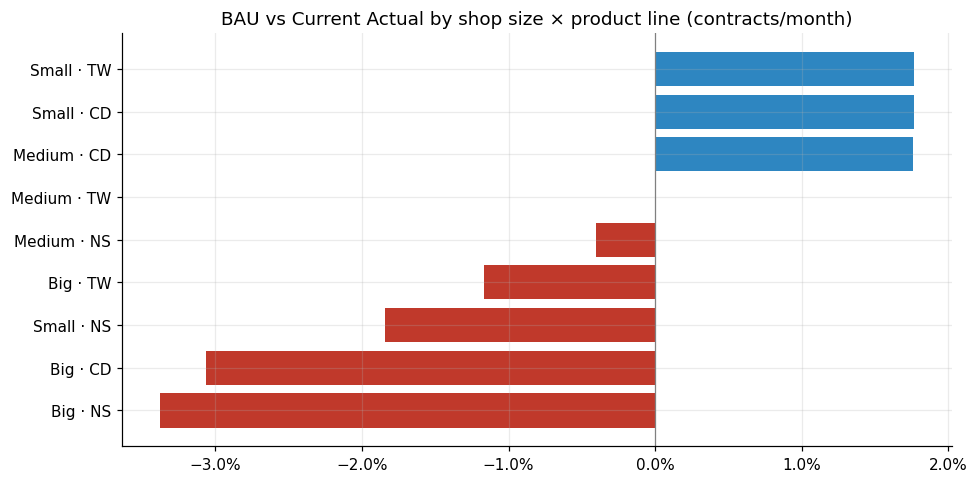

In [34]:
path = pd.DataFrame({"BAU contract (shop vật lý)": p_[monthly_cols].sum().to_numpy(),
                     "BAU funded (tỷ đồng)": (p_[monthly_cols].mul(p_["ticket_bau"], axis=0).sum() / 1e9).to_numpy()},
                    index=[m.strftime("%m/%Y") for m in FC_MONTHS])
path.loc["TB 6 tháng"] = path.mean()
display(path)
by_trend = (p_.groupby("trend_label").agg(shops=("bau_contracts", "size"), ca=("ca_signed_contracts", "sum"),
                                          bau=("bau_contracts", "sum"))
              .assign(bau_vs_ca=lambda d: d["bau"] / d["ca"].replace(0, np.nan) - 1,
                      share_of_bau=lambda d: d["bau"] / d["bau"].sum()))
display(by_trend)
head = (p_.groupby(["shop_category", "SALESROOM_PRODUCT"])
          .agg(shops=("bau_contracts", "size"), ca=("ca_signed_contracts", "sum"), bau=("bau_contracts", "sum"),
               bau_funded_bn=("bau_funded_volume", lambda s: s.sum() / 1e9))
          .assign(bau_vs_ca=lambda d: d["bau"] / d["ca"] - 1))
display(head)
fig, ax = plt.subplots(figsize=(9, 4.5))
hb = head["bau_vs_ca"].sort_values()
ax.barh([f"{a} · {b}" for a, b in hb.index], hb.to_numpy(), color=np.where(hb.to_numpy() < 0, "#c0392b", "#2e86c1"))
ax.axvline(0, color="grey", lw=0.8); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("BAU vs Current Actual by shop size × product line (contracts/month)")
plt.tight_layout(); plt.show()

### GĐ10.3 · Giải thích điểm "ngược trực giác"
**Mục đích:** chuẩn bị câu trả lời cho câu hỏi giám khảo rất dễ đặt ra: *"Vì sao shop đang đi lên lại có BAU thấp hơn hiện tại, còn shop đi xuống lại cao hơn?"*

**Cách làm:** so BAU với CA cho shop lớn và shop nhỏ trong hai nhóm nhãn; xem chuỗi 6 tháng của 2 shop lớn tiêu biểu.

In [35]:
tl = p_.loc[p_["trend_label"].isin(["Đi lên", "Đi xuống"])].copy()
tl["quy mô"] = np.where(tl["ca_signed_contracts"].ge(10), "Lớn (CA ≥ 10/tháng)", "Nhỏ (CA < 10/tháng)")
display(tl.groupby(["trend_label", "quy mô"]).agg(shops=("bau_contracts", "size"), ca=("ca_signed_contracts", "sum"),
                                                  bau=("bau_contracts", "sum"))
          .assign(bau_vs_ca=lambda d: d["bau"] / d["ca"].replace(0, np.nan) - 1))
big2 = [s for s in ["122941849", "118655027"] if s in panel["shop_id"].values]
if big2:
    view = (panel.loc[panel["shop_id"].isin(big2) & panel["month"].ge("2026-04-01")]
                 .pivot(index="shop_id", columns="month", values="signed_contracts")
                 .rename(columns=lambda m: m.strftime("%m/%Y")))
    view["CA"] = bau.loc[view.index, "ca_signed_contracts"]
    view["BAU"] = bau.loc[view.index, "bau_contracts"]
    view["nhãn"] = bau.loc[view.index, "trend_label"]
    display(view)

shops         ca        bau  bau_vs_ca
trend_label quy mô                                                     
Đi lên      Lớn (CA ≥ 10/tháng)    153 3,365.0000 3,188.8884    -0.0523
            Nhỏ (CA < 10/tháng)    276 1,125.6667   922.6363    -0.1804
Đi xuống    Lớn (CA ≥ 10/tháng)     26   863.6667   866.5993     0.0034
            Nhỏ (CA < 10/tháng)    302   491.6667   792.9504     0.6128

month,04/2026,05/2026,06/2026,07/2026,08/2026,09/2026,CA,BAU,nhãn
shop_id,,,,,,,,,
118655027,514.0000,605.0000,358.0000,289.0000,413.0000,351.0000,351.0000,339.2656,Đi xuống
122941849,67.0000,119.0000,122.0000,180.0000,184.0000,174.0000,179.3333,173.3816,Đi lên


**Phân tích kết quả GĐ10**

**① Pattern**
- **[Tin cậy Cao · Giá trị Cao]** Shop "Đứng yên" chiếm **61,8%** tổng BAU; shop "Đi lên" chiếm 10,9%; shop "Đi xuống" chiếm 4,4%; shop chưa đủ dữ liệu chiếm 21,8%.
- **[Tin cậy Cao · Giá trị Cao]** Theo quy mô trong hai nhóm nhãn:
  - Đi lên, shop **lớn** (153 shop): BAU −5,2% so với CA; shop **nhỏ** (276 shop): −18,0%.
  - Đi xuống, shop **lớn** (26 shop): BAU +0,3%; shop **nhỏ** (302 shop): +61,3%.
- **[Tin cậy Cao · Giá trị TB]** Hai shop lớn tiêu biểu: shop 122941849 (Đi lên) bán 67 → 184 → 174, CA 179, BAU **173**; shop 118655027 (Đi xuống) bán 514 → 605 → 351, CA 351, BAU **339**.
- **[Tin cậy Cao · Giá trị TB]** Theo cỡ × ngành: **Big CD −3,1%**, **Big NS −3,4%**, Big TW −1,2%; Medium/Small CD **+1,8%**.

**② Insight**
- **[Tin cậy Cao · Giá trị Cao]** Với **shop lớn**, BAU bám sát mức hiện tại, chỉ cộng/trừ phần xu hướng có bằng chứng. Chênh lệch lớn chỉ xảy ra ở **shop nhỏ**, nơi 3 tháng gần nhất phần lớn là nhiễu (rơi về 0 hoặc nhảy lên đột ngột), nên BAU kéo về mức 6 tháng đúng như κ ≈ 0,35. *Câu trả lời cho giám khảo:* "Chúng tôi không ngoại suy biến động ngắn hạn của shop nhỏ, vì lịch sử 10 thời điểm chứng minh nó không kéo dài."
- **[Tin cậy TB · Giá trị Cao]** **Shop Big đang chững lại** (BAU thấp hơn CA ở cả 3 ngành), trong khi shop vừa và nhỏ ngành CD còn nhích lên. Nếu năng lực của shop Big không đổi, khoảng cách giữa Attainable và BAU của nhóm này sẽ lớn.

**③ Câu hỏi · Giả thuyết · Bàn giao**
- **Giả thuyết → Bước 3/5:** shop Big chững vì thiếu SA so với lượng khách (Staffing) hay vì chất lượng lead giảm (Demand)? Bước 5 kiểm tra bằng `headcount_sa` và `conversion_rate` của chính bảng KPI.
- **Cách trình bày:** dùng câu chuẩn của 1 shop ví dụ cùng biểu đồ "Actual + BAU" làm bằng chứng chính của Bước 2; công thức và kiểm tra nội bộ để ở phần phụ lục.

---
## GĐ11 · Xuất file & bàn giao

**Mục đích giai đoạn:** các bước sau dùng được ngay, đúng tên cột; nộp được vào ZIP *Analysis Files*.

**Phương pháp tổng thể:** xuất 4 file (11.1) → từ điển cột và kiểm tra cuối (11.2).

| File | Nội dung | Ai dùng, dùng cột nào |
|---|---|---|
| `shop_bau.csv` | 1 dòng/shop: trạng thái, mức nền, trend, nhãn, CA, BAU contract/funded, BAU cross-sell, đóng góp tổng, câu lời thường, đường 6 tháng | **B3**: `bau_contracts` (Attainable ≥ BAU) · **B5**: `bau_contracts`, `bau_funded_volume`, `bau_total_contribution_*` · **B6**: `trend_label` |
| `shop_bau_monthly.csv` | shop × tháng 10/2026–03/2027 | Biểu đồ; B7 |
| `bau_params.json` | κ (và theo từng gốc), B, hệ số tháng, vòng đời, φ, k, kết quả kiểm tra nội bộ, CFG | Appendix; B7 (sensitivity) |
| `shop_bau_dictionary.csv` | Từ điển cột | Cả nhóm |

### GĐ11.1 · Xuất file
**Mục đích:** lưu kết quả và tham số.

**Cách làm:** ghi CSV (utf-8-sig để Excel đọc đúng tiếng Việt) và JSON tham số.

In [36]:
out_cols = (["shop_category", "salesroom_model", "SALESROOM_PRODUCT", "salesroom_province", "salesroom_area",
             "first_seen_month", "shop_age_group", "data_status", "bau_method", "n_valid", "level", "g_raw", "z",
             "trend_label", "B_shrink", "g_shrunk", "ca_signed_contracts", "ca_funded_volume",
             "ca_cross_sell_contracts", "ca_cross_sell_funded_volume", "ca_cross_sell_booked_elsewhere_or_online",
             "bau_contracts", "bau_vs_ca", "ticket_bau", "bau_funded_volume", "bau_xsell_contracts",
             "bau_xsell_funded_volume", "bau_xsell_elsewhere_contracts", "bau_xsell_elsewhere_funded",
             "bau_total_contribution_contracts", "bau_total_contribution_funded", "bau_statement_vi",
             "bau_statement_en"] + monthly_cols)
bau_out = bau[out_cols].rename_axis("shop_id").reset_index()
bau_out.to_csv(os.path.join(OUT_DIR, "shop_bau.csv"), index=False, encoding="utf-8-sig")
monthly = (F_all.reindex(bau.index).rename_axis("shop_id").reset_index()
                .melt(id_vars="shop_id", var_name="month", value_name="bau_contracts")
                .join(bau["ticket_bau"], on="shop_id"))
monthly["bau_funded_volume"] = monthly["bau_contracts"] * monthly["ticket_bau"]
monthly.drop(columns="ticket_bau").to_csv(os.path.join(OUT_DIR, "shop_bau_monthly.csv"), index=False)
params = {
    "kappa": KAPPA, "kappa_by_origin": kappa_tab.to_dict("records"),
    "season_B": season_main["B"], "season_corr_2025_2026": season_main["corr_years"],
    "season_factor_forecast": dict(zip(fc_factors["month"], fc_factors["S_m (cuối cùng)"].round(4))),
    "lifecycle": {k: LIFE_MAIN[k] for k in ("amp", "tau", "plateau", "K", "n_shops")},
    "zero_base_rates": zero_rates["rate"].round(4).to_dict(),
    "trend_mu": lt_main.attrs["mu"], "trend_tau": float(np.sqrt(lt_main.attrs["tau2"])),
    "phi_by_size": {str(k): v for k, v in lt_main.attrs["phi"].items()}, "ticket_credibility_k": K_CRED,
    "xsell_else_share_contracts": float(net_else_share), "xsell_else_share_funded": float(net_f_share),
    "internal_check_holdout_2026_03": check.to_dict("index"),
    "config": {k: (str(v) if not isinstance(v, (int, float)) else v) for k, v in CFG.items()},
}
with open(os.path.join(OUT_DIR, "bau_params.json"), "w", encoding="utf-8") as f:
    json.dump(params, f, ensure_ascii=False, indent=2, default=str)

### GĐ11.2 · Từ điển cột và kiểm tra cuối
**Hậu kiểm định:** đủ 1 dòng/shop, khớp số shop của Bước 1.

In [37]:
dictionary = pd.DataFrame([
    ("data_status / bau_method", "Tình trạng dữ liệu tại 09/2026 và cách tính BAU áp dụng (quy tắc biên GĐ7.2)"),
    ("level", "Mức nền: contract/tháng chuẩn 30,44 ngày, đã khử mùa vụ và quy về 'shop đã ổn định', TB 04–09/2026"),
    ("g_raw / z", "Xu hướng thô %/tháng của 6 tháng gần nhất và thống kê kiểm định z"),
    ("trend_label", "Đi lên / Đi xuống (|z|>1,96) / Đứng yên / Ngủ đông (≥3 tháng toàn 0) / Chưa đủ dữ liệu / Chưa phát sinh doanh số"),
    ("B_shrink / g_shrunk", "Mức tin vào trend riêng của shop (0–1) và trend sau lọc nhiễu, chặn ±15%/tháng"),
    ("ca_*", "Current Actual = TB 07–09/2026 (QƯ3), lấy nguyên từ Bước 1"),
    ("bau_contracts", "BAU = TB contract/tháng 10/2026–03/2027 (bán tại shop, theo tháng ký)"),
    ("bau_vs_ca", "BAU / CA − 1"),
    ("ticket_bau / bau_funded_volume", "Ticket credibility và BAU funded volume (đồng/tháng)"),
    ("bau_xsell_*", "BAU cross-sell ghi công cho shop tạo lead; *_elsewhere = phần ký ở shop khác/online"),
    ("bau_total_contribution_*", "Bán tại shop + cross-sell ký nơi khác (không double count)"),
    ("bau_statement_vi / _en", "Câu lời thường mô tả BAU"),
    ("bau_contracts_YYYY_MM", "Đường dự báo theo tháng"),
], columns=["cột", "ý nghĩa"])
dictionary.to_csv(os.path.join(OUT_DIR, "shop_bau_dictionary.csv"), index=False, encoding="utf-8-sig")
display(dictionary)
assert bau_out["shop_id"].is_unique and len(bau_out) == kpi["shop_id"].nunique()
print("Đã xuất:", sorted(f for f in os.listdir(OUT_DIR) if not f.endswith(".ipynb")), "| shop_bau.csv:", bau_out.shape)

,cột,ý nghĩa
0,data_status / bau_method,Tình trạng dữ liệu tại 09/2026 và cách tính BAU áp dụng (quy tắc biên GĐ7.2)
1,level,"Mức nền: contract/tháng chuẩn 30,44 ngày, đã khử mùa vụ và quy về 'shop đã ổn định', TB 04–09/2026"
2,g_raw / z,Xu hướng thô %/tháng của 6 tháng gần nhất và thống kê kiểm định z
3,trend_label,"Đi lên / Đi xuống (|z|>1,96) / Đứng yên / Ngủ đông (≥3 tháng toàn 0) / Chưa đủ dữ liệu / Chưa phát sinh doanh số"
4,B_shrink / g_shrunk,"Mức tin vào trend riêng của shop (0–1) và trend sau lọc nhiễu, chặn ±15%/tháng"
5,ca_*,"Current Actual = TB 07–09/2026 (QƯ3), lấy nguyên từ Bước 1"
6,bau_contracts,"BAU = TB contract/tháng 10/2026–03/2027 (bán tại shop, theo tháng ký)"
7,bau_vs_ca,BAU / CA − 1
8,ticket_bau / bau_funded_volume,Ticket credibility và BAU funded volume (đồng/tháng)
9,bau_xsell_*,BAU cross-sell ghi công cho shop tạo lead; *_elsewhere = phần ký ở shop khác/online


Đã xuất: ['bau_params.json', 'shop_bau.csv', 'shop_bau_dictionary.csv', 'shop_bau_monthly.csv'] | shop_bau.csv: (11753, 40)


---
## Tổng kết Bước 2

**Kết quả chính (TB/tháng, 10/2026–03/2027):**

| Chỉ tiêu | CA 07–09/2026 | BAU | BAU/CA − 1 |
|---|---|---|---|
| Contract bán tại shop (shop vật lý) | 37.664 | **37.734** | +0,2% |
| Funded volume tại shop | 516,9 tỷ | **520,4 tỷ** | +0,7% |
| Contract cross-sell (ghi công) | 8.573 | 8.992 | +4,9% |
| Đóng góp tổng (tại shop + cross-sell ký nơi khác) | — | **39.272 contract · 539,0 tỷ** | — |

**5 phát hiện xếp theo độ tin cậy và giá trị:**
1. **[Tin cậy Cao · Giá trị Cao]** Tăng trưởng 2025–2026 đến **103% từ mở shop**; bình quân mỗi shop −11% → nếu không làm gì khác, mạng lưới hiện tại **đi ngang**.
2. **[Tin cậy Cao · Giá trị Cao]** Shop mới có **đỉnh khai trương +51%** rồi giảm về mức ổn định sau khoảng 4–6 tháng. Bỏ thành phần này thì BAU lệch +7,0%.
3. **[Tin cậy Cao · Giá trị Cao]** Chỉ **khoảng 1/3** trend gần đây còn kéo dài (κ = 0,355, ổn định qua 10 thời điểm gốc). Kéo dài trend thô theo nghĩa đen làm BAU lệch +49%.
4. **[Tin cậy Cao · Giá trị Cao]** Chỉ **8,3%** shop có trend rõ ràng; **328 shop "Đi xuống"** là danh sách cảnh báo sớm (đã loại phần giảm tự nhiên sau khai trương).
5. **[Tin cậy TB · Giá trị TB]** Mùa vụ ngoài số ngày **không lặp lại** (tương quan −0,15, B = 0,17). 11/2025 là cú sốc riêng CD/NS. Tết tác động **ngược chiều** lên CD và TW.

**Tiền đề bàn giao cho các bước khác:**
- **B3:** Attainable ≥ BAU; không so shop 1–3 tháng tuổi bằng số thô; 2.173 shop chưa từng bán (25% shop Aldi) là gap kích hoạt.
- **B5:** gap = Attainable − `bau_contracts` / `bau_funded_volume` (hoặc `bau_total_contribution_*`); kiểm tra nguyên nhân của 328 shop Đi xuống.
- **B6:** nhãn Đi xuống và Ngủ đông là nhóm can thiệp khác nhau; cân nhắc thời điểm can thiệp theo ngành (CD trước Tết, TW tháng 12 và tháng 3).
- **B7:** dùng `run_backtest()` để so với NAIVE3, chạy nhiều gốc, sensitivity (`kappa`, `shrink`, `window`, `use_life`), gắn nhãn tin cậy theo quy mô (GĐ3.4).

**Giới hạn cần nói thẳng:** (i) chỉ có shop Active trong dữ liệu (survivorship); (ii) mới quan sát được 1 mùa Tết; (iii) cross-sell chỉ có 6 tháng lịch sử; (iv) BAU không gồm shop sẽ mở mới trong 10/2026–03/2027.